<a href="https://colab.research.google.com/github/kvmmn/_COM7022_MachineLearning/blob/main/COM7022%20-%20Assignment/COM7022_Clustering_25199053.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# COM7022 Machine Learning: Product Clustering for an E-commerce Catalogue

**Student ID:** 25199053 · **Module:** COM7022 Machine Learning · **Task 1:** Practical Project

This notebook groups the product listings in `Sales-[5444].csv` by their characteristics and sales performance. It follows the steps of a standard machine learning investigation:

1. Data import
2. Descriptive statistics and data quality checks
3. Pre-processing
4. Feature selection
5. Principal Component Analysis (PCA)
6. K-Means
7. Hierarchical clustering
8. DBSCAN
9. HDBSCAN
10. TabClustPFN (tabular foundation model)
11. Model comparison and validation
12. Final model and cluster profiles
13. Segment rules (how much of the segmentation is thresholds)
14. Report diagrams

**How to run on Google Colab:** upload `Sales-[5444].csv` into the Colab file panel (or let the upload cell below ask for it), then choose *Runtime > Run all*. All figures and tables are saved into an `output/` folder next to the notebook. Random seeds are fixed (274) so the results repeat.

## 0. Set-up

In [1]:
# Standard libraries
import os
import re
import json
import warnings
from pathlib import Path

# Data handling and plotting
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import sklearn

# Machine learning tools
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN, HDBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet, set_link_color_palette
from scipy.spatial.distance import pdist
from scipy.stats import skew

warnings.filterwarnings("ignore", category=FutureWarning)

# One seed for every random step, so a re-run gives the same numbers. 274 is my fixed choice for the whole project.
SEED = 274
np.random.seed(SEED)

print("Python libraries used in this run:")
print("pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__,
      "| scipy", scipy.__version__, "| matplotlib", matplotlib.__version__, "| seaborn", sns.__version__)

Python libraries used in this run:
pandas 3.0.5 | numpy 2.5.3 | scikit-learn 1.9.1 | scipy 1.18.1 | matplotlib 3.11.2 | seaborn 0.13.2


In [2]:
# Arden University palette (Midnight / Tiffany), the same visual system used in my earlier modules
MIDNIGHT = "#002B49"
TIFFANY = "#66C9BA"
TIFFANY_DEEP = "#3AA89A"
MIDNIGHT_SOFT = "#1A4A6B"
TEAL = "#0E7C8B"
MIST = "#E6F5F2"
PAPER = "#F7FAFB"
MUTE = "#5A6B75"
GRID = "#D5DEE3"
NOISE_GREY = "#A7B4BC"

# One fixed colour per K-Means segment, used in every chart and in the report (index = cluster label):
# 0 Premium = steel blue, 1 Budget = ochre, 2 Best-sellers = tiffany, 3 Low-stock = terracotta.
CLUSTER_COLOURS = ["#2F6690", "#C99A2E", TIFFANY_DEEP, "#C8553D", MIDNIGHT]
MODEL_COLOURS = {"K-Means": MIDNIGHT, "Hierarchical (Ward)": "#2F6690", "DBSCAN": "#8FA3B1",
                 "HDBSCAN": TIFFANY_DEEP, "TabClustPFN (auto k)": "#C99A2E", "TabClustPFN (k = 4)": "#E2C37E"}
ARDEN_CMAP = matplotlib.colors.LinearSegmentedColormap.from_list(
    "arden", [MIST, TIFFANY, TIFFANY_DEEP, MIDNIGHT_SOFT, MIDNIGHT])
ARDEN_DIVERGING = matplotlib.colors.LinearSegmentedColormap.from_list(
    "arden_div", ["#C8553D", "#F3D9D2", "#FFFFFF", "#CFE3EE", MIDNIGHT_SOFT])

# Print-ready figure system. Every chart is drawn at its final printed size (the report's text width is
# 6.6 in = 16.8 cm), so labels are the same 8.5 pt in every figure and nothing is rescaled in the report.
TEXT_WIDTH = 6.6
NARROW = 4.6
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Carlito", "Calibri", "Arial", "DejaVu Sans"],
    "font.size": 8.5,
    "axes.titlesize": 9,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.titlepad": 6,
    "axes.labelsize": 8.5,
    "xtick.labelsize": 7.5,
    "ytick.labelsize": 7.5,
    "legend.fontsize": 7.5,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#9AAAB4",
    "axes.linewidth": 0.6,
    "axes.labelcolor": MIDNIGHT,
    "axes.titlecolor": MIDNIGHT,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.5,
    "xtick.color": MUTE,
    "ytick.color": MUTE,
    "xtick.major.size": 2.5,
    "ytick.major.size": 2.5,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
    "lines.linewidth": 1.4,
    "lines.markersize": 4,
    "patch.linewidth": 0.4,
    "legend.frameon": False,
    "legend.handlelength": 1.4,
    "figure.dpi": 100,
    "savefig.dpi": 300,
    "savefig.bbox": "standard",
    "savefig.facecolor": "white",
    "figure.constrained_layout.use": True,
    "figure.constrained_layout.h_pad": 0.04,
    "figure.constrained_layout.w_pad": 0.04,
})


def panel(ax, letter, title):
    # Panel titles are lettered so the report caption can refer to (a), (b), (c)
    ax.set_title("(" + letter + ")  " + title)


# Output folders for the figures and tables used in the report
OUTPUT_DIR = Path("output")
FIG_DIR = OUTPUT_DIR / "figures"
TABLE_DIR = OUTPUT_DIR / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)


def save_figure(fig, filename):
    # Save every chart with the same settings so the report pack is consistent
    fig.savefig(FIG_DIR / filename)
    print("Saved:", FIG_DIR / filename)


def save_table(table, filename):
    table.to_csv(TABLE_DIR / filename)
    print("Saved:", TABLE_DIR / filename)

## 1. Data import

The notebook first looks for the CSV next to the notebook. On Colab, if the file has not been uploaded yet, it opens an upload dialog. The import of `google.colab` is wrapped in `try` so the same notebook also runs on a normal Jupyter install.

In [3]:
DATA_FILE = "Sales-[5444].csv"
candidate_paths = [Path(DATA_FILE), Path("..") / DATA_FILE, Path("/content") / DATA_FILE]

data_path = None
for path in candidate_paths:
    if path.exists():
        data_path = path
        break

if data_path is None:
    try:
        from google.colab import files  # only available on Colab
        print("CSV not found. Please upload", DATA_FILE)
        uploaded = files.upload()
        data_path = Path(list(uploaded.keys())[0])
    except ImportError:
        raise FileNotFoundError("Place " + DATA_FILE + " next to this notebook.")

raw = pd.read_csv(data_path)
print("Loaded:", data_path)
print("Shape:", raw.shape[0], "rows x", raw.shape[1], "columns")
raw.head()

Loaded: Sales-[5444].csv
Shape: 1000 rows x 10 columns


,Item_Name,details,Catatory,price,priceWithCurrency,available,text,sold,lastUpdated,itemLocation
0,Dior,Christian Dior Sauvage Men's EDP 3.4 oz Fragra...,Eau de Parfum,84.99,US $84.99/ea,10.0,More than 10 available / 116 sold,NaN,"May 24, 2024 10:03:04 PDT","Allen Park, Michigan, United States"
1,AS SHOW,A-v-entus Eau de Parfum 3.3 oz 100ML Millesime...,Eau de Parfum,NaN,US $109.99,8.0,8 available / 48 sold,48.0,"May 23, 2024 23:07:49 PDT","Atlanta, Georgia, Canada"
2,Unbranded,HOGO BOSS cologne For Men 3.4 oz,Eau de Toilette,100.00,US $100.00,10.0,More than 10 available / 27 sold,27.0,"May 22, 2024 21:55:43 PDT","Dearborn, Michigan, United States"
3,Giorgio Armani,Acqua Di Gio by Giorgio Armani 6.7 Fl oz Eau D...,Eau de Toilette,NaN,US $44.99/ea,2.0,2 available / 159 sold,159.0,"May 24, 2024 03:30:43 PDT","Reinholds, Pennsylvania, United States"
4,Lattafa,Lattafa Men's Hayaati Al Maleky EDP Spray 3.4 ...,Fragrances,16.91,NaN,NaN,Limited quantity available / 156 sold,NaN,"May 24, 2024 07:56:25 PDT","Brooklyn, New York, United States"


In [4]:
# Column types and non-null counts
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Item_Name          999 non-null    str    
 1   details            1000 non-null   str    
 2   Catatory           997 non-null    str    
 3   price              995 non-null    float64
 4   priceWithCurrency  999 non-null    str    
 5   available          889 non-null    float64
 6   text               997 non-null    str    
 7   sold               992 non-null    float64
 8   lastUpdated        947 non-null    str    
 9   itemLocation       1000 non-null   str    
dtypes: float64(3), str(7)
memory usage: 78.3 KB


**Unit of observation.** Each row is one product listing (a seller's offer for one fragrance product). The clustering therefore groups *listings*, not brands or customers. The columns are product information (`Item_Name` = brand, `details`, `Catatory`), pricing (`price`, `priceWithCurrency`), availability and sales (`available`, `text`, `sold`), update history (`lastUpdated`) and location (`itemLocation`).

## 2. Descriptive statistics and data quality

In [5]:
# Missing values per column, as counts and percentages
missing = pd.DataFrame({
    "missing_count": raw.isna().sum(),
    "missing_pct": (raw.isna().mean() * 100).round(1),
})
missing = missing.sort_values("missing_count", ascending=False)
print("Full-row duplicates:", raw.duplicated().sum())
print("Duplicate listing descriptions:", raw["details"].duplicated().sum())
save_table(missing, "table01_missing_values.csv")
missing

Full-row duplicates: 0
Duplicate listing descriptions: 34
Saved: output/tables/table01_missing_values.csv


,missing_count,missing_pct
available,111,11.1
lastUpdated,53,5.3
sold,8,0.8
price,5,0.5
text,3,0.3
Catatory,3,0.3
priceWithCurrency,1,0.1
Item_Name,1,0.1
details,0,0.0
itemLocation,0,0.0


Saved: output/figures/fig01_missing_values.png


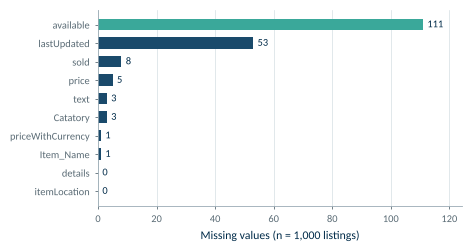

In [6]:
# Figure 1: where the gaps are
data = missing["missing_count"][::-1]
colours = [GRID if v == 0 else MIDNIGHT_SOFT for v in data.values]
colours[-1] = TIFFANY_DEEP          # the biggest gap drives a pre-processing decision
fig, ax = plt.subplots(figsize=(NARROW, 2.4))
bars = ax.barh(data.index, data.values, color=colours, height=0.62)
for bar, value in zip(bars, data.values):
    ax.text(bar.get_width() + 1.5, bar.get_y() + bar.get_height() / 2, str(value), va="center",
            color=MIDNIGHT, fontsize=7.5)
ax.set_xlim(0, data.max() * 1.12)
ax.set_xlabel("Missing values (n = 1,000 listings)")
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
save_figure(fig, "fig01_missing_values.png")
plt.show()

In [7]:
# Descriptive statistics for the numeric columns, including skewness
numeric_cols = ["price", "available", "sold"]
desc = raw[numeric_cols].describe().T
desc["median"] = raw[numeric_cols].median()
desc["skewness"] = [skew(raw[c].dropna()) for c in numeric_cols]
desc = desc[["count", "mean", "median", "std", "min", "25%", "75%", "max", "skewness"]].round(2)
save_table(desc, "table02_descriptive_statistics_raw.csv")
desc

Saved: output/tables/table02_descriptive_statistics_raw.csv


,count,mean,median,std,min,25%,75%,max,skewness
price,995.0,46.43,35.71,35.55,3.0,22.99,59.00,259.09,2.04
available,889.0,20.05,10.00,61.55,2.0,5.00,10.00,842.00,8.15
sold,992.0,775.25,49.50,3211.43,1.0,14.00,324.75,54052.00,9.70


In [8]:
# Text and category columns: how many distinct values, and the most common ones
for col in ["Item_Name", "Catatory", "itemLocation"]:
    print(col, "->", raw[col].nunique(), "distinct values")
print()
print("Category labels (top 15 of", raw["Catatory"].nunique(), "):")
print(raw["Catatory"].value_counts().head(15))

Item_Name -> 246 distinct values
Catatory -> 63 distinct values
itemLocation -> 276 distinct values

Category labels (top 15 of 63 ):
Catatory
Eau de Toilette    444
Eau de Parfum      285
Eau de Cologne      56
Perfume             50
Fragrances          32
Eau De Parfum       15
Parfum              13
Eau de Perfume      10
Eau De Toilette      9
Gift Sets            6
Cologne              5
PARFUM               4
Body Spray           4
/                    3
Aftershave           3
Name: count, dtype: int64


In [9]:
# The 'text' column holds the availability and sales wording shown on the listing.
# Replacing digits with N shows the small number of patterns behind 1,000 rows.
patterns = raw["text"].fillna("<missing>").str.split("/").str[0].str.strip()
patterns = patterns.str.replace(r"\d[\d,]*", "N", regex=True)
print(patterns.value_counts())
print()
print("Currencies in priceWithCurrency:")
print(raw["priceWithCurrency"].str.extract(r"^([A-Z]+ ?\$)")[0].value_counts())

text
N available                                     592
More than N available                           297
Limited quantity available                       59
Last One                                         47
<missing>                                         3
More than N lots available (N items per lot)      2
Name: count, dtype: int64

Currencies in priceWithCurrency:
0
US $    996
C $       3
Name: count, dtype: int64


**What the checks show.**

- There are no full-row duplicates, so no rows need to be removed for that reason.
- `price` and `sold` are both right-skewed, `sold` extremely so (a few listings sold tens of thousands of units while the median is about 50). Distance-based clustering would be dominated by those few rows unless the scale is compressed.
- `available` has the largest gap. The `text` column explains it: the missing rows are listings showing *"Limited quantity available"*, *"Last One"* or lot-based wording instead of a number. It also shows that *"More than 10 available"* was stored as 10, so the stock figure is **capped**, not exact.
- `Catatory` has dozens of labels that are spelling or capitalisation variants of the same product type.
- `priceWithCurrency` contains three Canadian-dollar prices among US-dollar prices.

Saved: output/figures/fig02_raw_distributions.png


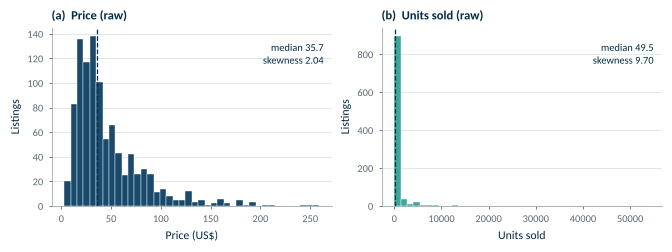

In [10]:
# Figure 2: raw distributions of price and units sold
fig, axes = plt.subplots(1, 2, figsize=(TEXT_WIDTH, 2.4))
for ax, col, colour, letter, title, xlabel in [
        (axes[0], "price", MIDNIGHT_SOFT, "a", "Price (raw)", "Price (US$)"),
        (axes[1], "sold", TIFFANY_DEEP, "b", "Units sold (raw)", "Units sold")]:
    values = raw[col].dropna()
    ax.hist(values, bins=40, color=colour, edgecolor="white", linewidth=0.3)
    ax.axvline(values.median(), color=MIDNIGHT, linestyle="--", linewidth=0.9)
    ax.text(0.97, 0.92, "median " + format(values.median(), ",.1f") + "\nskewness " + format(skew(values), ".2f"),
            transform=ax.transAxes, ha="right", va="top", fontsize=7.5, color=MIDNIGHT)
    panel(ax, letter, title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Listings")
save_figure(fig, "fig02_raw_distributions.png")
plt.show()

## 3. Pre-processing

Every cleaning step below is recorded in a small log, so the before and after counts can be checked. The guiding rule is to **recover** values from other columns of the same row before imputing, and to impute only where the gap is small and the reason is understood.

In [11]:
df = raw.copy()
cleaning_log = []


def log_step(step, rows_affected, note):
    cleaning_log.append({"step": step, "rows_affected": int(rows_affected), "note": note})


# 3.1 Price: recover missing prices from priceWithCurrency (same listing, same number)
price_from_text = df["priceWithCurrency"].str.extract(r"\$([\d,]+\.?\d*)")[0]
price_from_text = price_from_text.str.replace(",", "").astype(float)
recovered = df["price"].isna() & price_from_text.notna()
df.loc[recovered, "price"] = price_from_text[recovered]
log_step("Recover price from priceWithCurrency", recovered.sum(), "Exact same value, only stored in text form")

# Check: where both exist, do they agree?
both = df["price"].notna() & price_from_text.notna()
print("Price disagreements where both exist:", (abs(df.loc[both, "price"] - price_from_text[both]) > 0.01).sum())

# 3.2 Currency: convert the three Canadian-dollar prices to USD
# Approximate May 2024 rate (1 CAD ~ 0.73 USD). Only 3 rows, so the exact rate barely matters.
CAD_TO_USD = 0.73
is_cad = df["priceWithCurrency"].fillna("").str.startswith("C")
df.loc[is_cad, "price"] = (df.loc[is_cad, "price"] * CAD_TO_USD).round(2)
log_step("Convert CAD prices to USD", is_cad.sum(), "Fixed rate 0.73, documented approximation")

Price disagreements where both exist: 0


In [12]:
# 3.3 Units sold: recover from the 'text' column ("... / 116 sold")
sold_from_text = df["text"].str.extract(r"([\d,]+) sold")[0].str.replace(",", "").astype(float)
recovered = df["sold"].isna() & sold_from_text.notna()
df.loc[recovered, "sold"] = sold_from_text[recovered]
log_step("Recover sold from text", recovered.sum(), "Exact value from the listing wording")

# Check the two sources agree everywhere else
both = df["sold"].notna() & sold_from_text.notna()
print("Sold disagreements where both exist:", (df.loc[both, "sold"] != sold_from_text[both]).sum())

# Listings whose text shows stock but no 'sold' part have not sold yet, so sold = 0
no_sales_yet = df["sold"].isna() & df["text"].notna() & ~df["text"].str.contains("sold", na=False)
df.loc[no_sales_yet, "sold"] = 0
log_step("Set sold = 0 where text shows stock but no sales", no_sales_yet.sum(), "Listing wording omits 'sold' when nothing has sold")

# Rows with no text and no sold value carry no sales or stock information at all
no_info = df["sold"].isna() & df["text"].isna()
print(df.loc[no_info, ["Item_Name", "price", "available", "text", "sold"]])
df = df[~no_info].copy()
log_step("Drop rows with no sales or stock information", no_info.sum(), "Cannot be placed on the sales-performance axis")

Sold disagreements where both exist: 1
              Item_Name   price  available text  sold
405  Jean Paul Gaultier  169.00        NaN  NaN   NaN
686              CHANEL   89.97        NaN  NaN   NaN
899             Bvlgari  250.00        NaN  NaN   NaN


In [13]:
# 3.4 Stock level: rebuild it from the listing wording so every row has a value.
# The marketplace hides exact numbers above 10 ("More than 10 available"), so I cap all
# stock values at 11, meaning "more than 10". This keeps the measure honest and comparable.
text = df["text"].fillna("")
stock = text.str.extract(r"^(\d+) available")[0].astype(float)
stock[text.str.startswith("More than")] = 11
stock[text.str.startswith("Last One")] = 1
capped_above_10 = (stock > 11).sum()
stock = stock.clip(upper=11)

# "Limited quantity available" and lot listings give no number: impute the median, but keep a flag
stock_imputed = stock.isna()
df["stock_imputed"] = stock_imputed.astype(int)
stock = stock.fillna(stock.median())
df["stock_level"] = stock

log_step("Stock: 'More than 10' coded as 11", text.str.startswith("More than").sum(), "Censored value, not exact")
log_step("Stock: explicit values above 10 capped at 11", capped_above_10, "Same scale as the censored rows")
log_step("Stock: 'Last One' coded as 1", text.str.startswith("Last One").sum(), "Wording means one unit left")
log_step("Stock: median imputation", stock_imputed.sum(), "Limited quantity / lot wording; flagged in stock_imputed")
print(df["stock_level"].value_counts().sort_index())

stock_level
1.0      47
2.0      55
3.0     109
4.0      46
5.0      62
6.0      43
7.0      34
8.0      45
9.0      98
10.0     44
11.0    414
Name: count, dtype: int64


In [14]:
# 3.5 Product type: collapse the messy category labels into six groups


def group_category(label):
    if pd.isna(label):
        return "Other"
    s = str(label).strip().lower()
    if s in ["", "/", "y", "does not apply", "unknown", "various", "assorted"]:
        return "Other"
    if "," in s or "/" in s:
        return "Other"                       # listings that name several types at once
    if "toil" in s or s == "edt":
        return "Eau de Toilette"             # includes the misspelling 'toillette'
    if "eau de parfum" in s or "eau de perfume" in s:
        return "Eau de Parfum"
    if "parfum" in s or "extrait" in s or "elixir" in s:
        return "Parfum / Extrait"
    if "cologne" in s or s == "edc":
        return "Cologne"
    if "perfume" in s or "fragrance" in s:
        return "Generic fragrance"
    return "Other"                           # body sprays, oils, deodorants, gift sets


df["product_type"] = df["Catatory"].apply(group_category)
print("Raw labels:", df["Catatory"].nunique(), "-> groups:", df["product_type"].nunique())
print(df["product_type"].value_counts())
log_step("Collapse category labels into 6 product types", df["Catatory"].notna().sum(), "Case, spelling and wording variants")

# 3.6 Brand: tidy whitespace; a missing brand is treated as 'Unbranded'
df["brand"] = df["Item_Name"].fillna("Unbranded").str.strip()
log_step("Missing brand set to 'Unbranded'", df["Item_Name"].isna().sum(), "Single row")

# 3.7 Location: keep the country (last part of 'City, State, Country')
df["country"] = df["itemLocation"].str.split(",").str[-1].str.strip()
df["ships_from_us"] = (df["country"] == "United States").astype(int)

# 3.8 Last update: parse dates (two month formats) and turn them into 'days since update'
dates = pd.to_datetime(df["lastUpdated"].str.replace(r" P[DS]T", "", regex=True), format="mixed", errors="coerce")
df["days_since_update"] = (dates.max() - dates).dt.total_seconds() / 86400
print("Unparsed or missing dates:", dates.isna().sum(), "| latest update:", dates.max())

# 3.9 Bottle size in ounces, parsed from the description (used for profiling, not clustering)
size = df["details"].str.extract(r"(\d+(?:\.\d+)?)\s*(?:fl\.?\s*)?oz", flags=re.IGNORECASE)[0].astype(float)
df["size_oz"] = size.where(size.between(0.3, 8.5))   # ignore implausible parses
print("Bottle size found for", df["size_oz"].notna().sum(), "listings")

Raw labels: 63 -> groups: 6
product_type
Eau de Toilette      459
Eau de Parfum        312
Generic fragrance     87
Cologne               69
Other                 41
Parfum / Extrait      29
Name: count, dtype: int64
Unparsed or missing dates: 50 | latest update: 2024-05-24 10:27:08
Bottle size found for 857 listings


In [15]:
# 3.10 Transform the skewed measures. log(1 + x) keeps zero sales valid (log of 0 is undefined).
df["log_price"] = np.log1p(df["price"])
df["log_sold"] = np.log1p(df["sold"])

skew_table = pd.DataFrame({
    "skew_before": [skew(df["price"]), skew(df["sold"])],
    "skew_after_log": [skew(df["log_price"]), skew(df["log_sold"])],
}, index=["price", "sold"]).round(2)
print(skew_table)

# Outliers: count them with the 1.5 x IQR rule on the raw scale, but keep them.
# Best-selling listings are exactly what the business wants to find, so removing them would be wrong.
q1, q3 = df["sold"].quantile([0.25, 0.75])
upper_fence = q3 + 1.5 * (q3 - q1)
print("Listings above the sold upper fence (" + str(round(upper_fence)) + "):", (df["sold"] > upper_fence).sum())
log_step("Log-transform price and sold", len(df), "Outliers kept; log scale limits their pull on distances")

cleaning_table = pd.DataFrame(cleaning_log)
save_table(cleaning_table, "table03_cleaning_log.csv")
print("Rows after cleaning:", len(df))
cleaning_table

       skew_before  skew_after_log
price         1.97            0.09
sold          9.72            0.52


Listings above the sold upper fence (784): 137
Saved: output/tables/table03_cleaning_log.csv
Rows after cleaning: 997


,step,rows_affected,note
0,Recover price from priceWithCurrency,5,"Exact same value, only stored in text form"
1,Convert CAD prices to USD,3,"Fixed rate 0.73, documented approximation"
2,Recover sold from text,2,Exact value from the listing wording
3,Set sold = 0 where text shows stock but no sales,3,Listing wording omits 'sold' when nothing has ...
4,Drop rows with no sales or stock information,3,Cannot be placed on the sales-performance axis
5,Stock: 'More than 10' coded as 11,299,"Censored value, not exact"
6,Stock: explicit values above 10 capped at 11,115,Same scale as the censored rows
7,Stock: 'Last One' coded as 1,47,Wording means one unit left
8,Stock: median imputation,62,Limited quantity / lot wording; flagged in sto...
9,Collapse category labels into 6 product types,994,"Case, spelling and wording variants"


Saved: output/figures/fig03_transformed_distributions.png


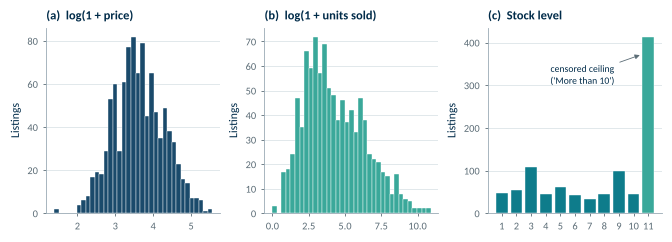

In [16]:
# Figure 3: distributions after the log transform
fig, axes = plt.subplots(1, 3, figsize=(TEXT_WIDTH, 2.3))
axes[0].hist(df["log_price"], bins=35, color=MIDNIGHT_SOFT, edgecolor="white", linewidth=0.3)
panel(axes[0], "a", "log(1 + price)")
axes[1].hist(df["log_sold"], bins=35, color=TIFFANY_DEEP, edgecolor="white", linewidth=0.3)
panel(axes[1], "b", "log(1 + units sold)")
counts = df["stock_level"].value_counts().sort_index()
axes[2].bar(counts.index, counts.values, color=[TIFFANY_DEEP if v == 11 else TEAL for v in counts.index],
            edgecolor="white", linewidth=0.3, width=0.8)
axes[2].annotate("censored ceiling\n('More than 10')", xy=(10.6, counts.loc[11] * 0.9), xytext=(6.5, counts.loc[11] * 0.78),
                 fontsize=7, color=MIDNIGHT, ha="center", va="center",
                 arrowprops=dict(arrowstyle="-|>", color=MUTE, lw=0.6, mutation_scale=7))
panel(axes[2], "c", "Stock level")
axes[2].set_xticks(range(1, 12))
for ax in axes:
    ax.set_ylabel("Listings")
save_figure(fig, "fig03_transformed_distributions.png")
plt.show()

In [17]:
# Descriptive statistics after cleaning (these are the numbers the models see, before scaling)
clean_desc = df[["price", "sold", "stock_level", "log_price", "log_sold", "days_since_update", "size_oz"]].describe().T
clean_desc["skewness"] = [skew(df[c].dropna()) for c in clean_desc.index]
clean_desc = clean_desc.round(2)
save_table(clean_desc, "table04_descriptive_statistics_clean.csv")
clean_desc

Saved: output/tables/table04_descriptive_statistics_clean.csv


,count,mean,std,min,25%,50%,75%,max,skewness
price,997.0,46.07,34.75,3.00,22.99,35.62,58.99,259.09,1.97
sold,997.0,771.63,3203.77,0.00,14.00,49.00,322.00,54052.00,9.72
stock_level,997.0,7.73,3.53,1.00,4.00,9.00,11.00,11.00,-0.57
log_price,997.0,3.63,0.67,1.39,3.18,3.60,4.09,5.56,0.09
log_sold,997.0,4.29,2.08,0.00,2.71,3.91,5.78,10.90,0.52
days_since_update,947.0,8.54,32.06,0.00,0.43,1.75,6.08,581.67,12.94
size_oz,857.0,3.58,1.21,0.33,3.30,3.40,3.70,8.00,0.86


## 4. Feature selection

The brief asks for groups based on **product characteristics and sales performance**. The candidate numeric features are listed below. Categorical columns (brand with 240+ values, product type, country) are kept for *describing* clusters afterwards rather than for building them, because one-hot columns mixed with continuous measures distort Euclidean distance and would let a single brand or country dominate the result.

Saved: output/figures/fig04_feature_correlation.png


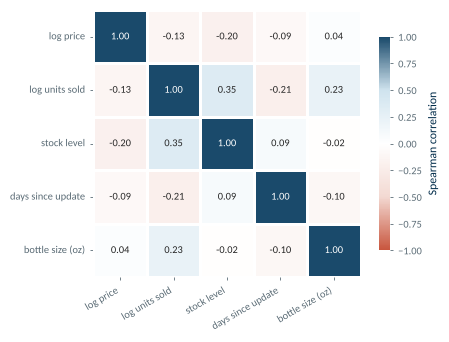

In [18]:
candidates = ["log_price", "log_sold", "stock_level", "days_since_update", "size_oz"]
corr = df[candidates].corr(method="spearman")

# Figure 4: Spearman correlation between candidate features
nice = {"log_price": "log price", "log_sold": "log units sold", "stock_level": "stock level",
        "days_since_update": "days since update", "size_oz": "bottle size (oz)"}
fig, ax = plt.subplots(figsize=(NARROW, 3.3))
sns.heatmap(corr.rename(index=nice, columns=nice), annot=True, fmt=".2f", cmap=ARDEN_DIVERGING, vmin=-1, vmax=1,
            linewidths=1, linecolor="white", square=True, annot_kws={"fontsize": 7.5},
            cbar_kws={"label": "Spearman correlation", "shrink": 0.8}, ax=ax)
ax.grid(False)
plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
save_figure(fig, "fig04_feature_correlation.png")
plt.show()

In [19]:
# Compare feature sets on the same footing: K-Means silhouette for k = 2..6.
# Rows with missing values in optional features are filled with the median only for this comparison.
feature_sets = {
    "A: price + sold": ["log_price", "log_sold"],
    "B: price + sold + stock": ["log_price", "log_sold", "stock_level"],
    "C: B + days since update": ["log_price", "log_sold", "stock_level", "days_since_update"],
    "D: B + bottle size": ["log_price", "log_sold", "stock_level", "size_oz"],
    "E: B + days + size": ["log_price", "log_sold", "stock_level", "days_since_update", "size_oz"],
}

rows = []
for name, cols in feature_sets.items():
    data = df[cols].fillna(df[cols].median())
    X_try = StandardScaler().fit_transform(data)
    row = {"feature_set": name, "n_features": len(cols)}
    for k in range(2, 7):
        labels_try = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit_predict(X_try)
        row["k=" + str(k)] = round(silhouette_score(X_try, labels_try), 3)
    rows.append(row)

feature_scan = pd.DataFrame(rows).set_index("feature_set")
save_table(feature_scan, "table05_feature_set_scan.csv")
feature_scan

Saved: output/tables/table05_feature_set_scan.csv


,n_features,k=2,k=3,k=4,k=5,k=6
feature_set,,,,,,
A: price + sold,2,0.352,0.377,0.357,0.351,0.354
B: price + sold + stock,3,0.337,0.297,0.307,0.307,0.297
C: B + days since update,4,0.310,0.315,0.281,0.288,0.284
D: B + bottle size,4,0.274,0.308,0.271,0.272,0.272
E: B + days + size,5,0.256,0.260,0.236,0.255,0.257


**Selected features: `log_price`, `log_sold`, `stock_level` (set B).**

- `log_price` describes the product's market position (budget to premium).
- `log_sold` is the sales-performance measure.
- `stock_level` is the availability status, which the brief lists as a key part of the data and which separates listings that are about to run out from ones with deep stock.
- `days_since_update` and `size_oz` lower the silhouette (Table 5), have gaps of their own, and add little business meaning: most bottles are 3.3 to 3.4 oz, and update dates fall within a few weeks. Set A scores slightly higher, but it ignores availability, which the business case needs, so the small loss in separation is accepted for a more useful segmentation.
- None of the three chosen features are strongly correlated with each other (Figure 4), so none is counted twice.

Because K-Means, Ward and DBSCAN all use Euclidean distance, the features must be on the same scale. I use **z-score standardisation** (mean 0, standard deviation 1). The lessons used min-max normalisation; I test that alternative in Section 9 as a sensitivity check.

In [20]:
FEATURES = ["log_price", "log_sold", "stock_level"]
scaler = StandardScaler()
X = scaler.fit_transform(df[FEATURES])
print("Feature matrix:", X.shape)
print("Means after scaling:", X.mean(axis=0).round(3))
print("Std after scaling:", X.std(axis=0).round(3))

Feature matrix: (997, 3)
Means after scaling: [-0.  0. -0.]
Std after scaling: [1. 1. 1.]


## 5. Principal Component Analysis

With three features PCA is not needed to reduce noise, but it gives a faithful 2D view for plotting clusters and shows which features drive the main directions of variation.

In [21]:
pca = PCA(random_state=SEED)
X_pca_full = pca.fit_transform(X)
explained = pca.explained_variance_ratio_
loadings = pd.DataFrame(pca.components_.T, index=FEATURES,
                        columns=["PC" + str(i + 1) for i in range(len(FEATURES))]).round(3)
print("Explained variance ratio:", explained.round(3))
print("Cumulative:", explained.cumsum().round(3))
save_table(loadings, "table06_pca_loadings.csv")
loadings

Explained variance ratio: [0.486 0.301 0.213]
Cumulative: [0.486 0.787 1.   ]
Saved: output/tables/table06_pca_loadings.csv


,PC1,PC2,PC3
log_price,-0.421,0.906,0.051
log_sold,0.636,0.335,-0.695
stock_level,0.647,0.260,0.717


Saved: output/figures/fig05_pca_variance_biplot.png


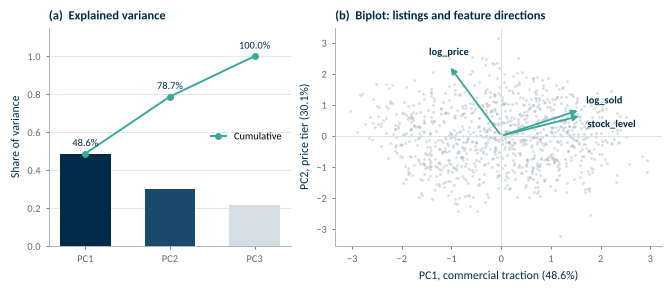

In [22]:
# Figure 5: explained variance (left) and feature loadings on PC1/PC2 (right)
X_2d = X_pca_full[:, :2]
fig, axes = plt.subplots(1, 2, figsize=(TEXT_WIDTH, 2.8), gridspec_kw={"width_ratios": [1, 1.35]})
pcs = ["PC1", "PC2", "PC3"]
axes[0].bar(pcs, explained, color=[MIDNIGHT, MIDNIGHT_SOFT, GRID], width=0.6)
axes[0].plot(pcs, explained.cumsum(), color=TIFFANY_DEEP, marker="o", label="Cumulative")
for i, v in enumerate(explained.cumsum()):
    axes[0].text(i, v + 0.04, str(round(v * 100, 1)) + "%", ha="center", color=MIDNIGHT, fontsize=7.5)
axes[0].set_ylim(0, 1.15)
axes[0].set_ylabel("Share of variance")
panel(axes[0], "a", "Explained variance")
axes[0].legend(loc="center right")

axes[1].scatter(X_2d[:, 0], X_2d[:, 1], s=4, color=NOISE_GREY, alpha=0.45, linewidths=0)
label_offset = {"log_price": (0, 0.25, "center", "bottom"), "log_sold": (0.12, 0.12, "left", "bottom"),
                "stock_level": (0.12, -0.12, "left", "top")}
for i, feature in enumerate(FEATURES):
    x, y = loadings.iloc[i, 0] * 2.5, loadings.iloc[i, 1] * 2.5
    axes[1].annotate("", xy=(x, y), xytext=(0, 0),
                     arrowprops=dict(arrowstyle="-|>", color=TIFFANY_DEEP, lw=1.3, mutation_scale=9))
    dx, dy, ha, va = label_offset[feature]
    axes[1].text(x + dx, y + dy, feature, color=MIDNIGHT, fontsize=7.5, fontweight="bold", ha=ha, va=va)
axes[1].axhline(0, color=GRID, linewidth=0.6)
axes[1].axvline(0, color=GRID, linewidth=0.6)
axes[1].set_xlabel("PC1, commercial traction (" + str(round(explained[0] * 100, 1)) + "%)")
axes[1].set_ylabel("PC2, price tier (" + str(round(explained[1] * 100, 1)) + "%)")
axes[1].grid(False)
panel(axes[1], "b", "Biplot: listings and feature directions")
save_figure(fig, "fig05_pca_variance_biplot.png")
plt.show()

## 6. K-Means

K-Means needs the number of clusters *k* in advance. I use two signals together: the **elbow** in inertia (within-cluster sum of squares, as taught in Lesson 8) and the **silhouette score**, which measures how much closer each point is to its own cluster than to the next one (range -1 to 1). Several random starts (`n_init=20`) reduce the risk of a poor initial placement of centroids.

In [23]:
k_values = range(2, 11)
kmeans_scan = []
for k in k_values:
    model = KMeans(n_clusters=k, n_init=20, random_state=SEED)
    labels_k = model.fit_predict(X)
    kmeans_scan.append({
        "k": k,
        "inertia": round(model.inertia_, 1),
        "silhouette": round(silhouette_score(X, labels_k), 3),
        "davies_bouldin": round(davies_bouldin_score(X, labels_k), 3),
        "calinski_harabasz": round(calinski_harabasz_score(X, labels_k), 1),
        "smallest_cluster": int(np.bincount(labels_k).min()),
    })
kmeans_scan = pd.DataFrame(kmeans_scan).set_index("k")
save_table(kmeans_scan, "table07_kmeans_k_scan.csv")
kmeans_scan

Saved: output/tables/table07_kmeans_k_scan.csv


,inertia,silhouette,davies_bouldin,calinski_harabasz,smallest_cluster
k,,,,,
2,1943.0,0.337,1.211,536.7,393
3,1501.0,0.297,1.228,493.4,298
4,1186.7,0.307,1.013,503.3,216
5,974.6,0.307,1.014,513.1,156
6,862.4,0.297,1.055,489.2,142
7,766.8,0.307,1.041,478.6,83
8,691.9,0.296,1.057,469.5,80
9,640.7,0.298,1.044,453.0,61
10,595.8,0.295,1.004,440.8,71


**Choice of k = 4.** No single index gives a sharp answer, which is normal when listings form a continuum rather than well-separated islands.

- The silhouette is highest at k = 2 (0.337), but two groups only split "sells well" from "sells poorly" and hide the price and stock differences the business asked about.
- From k = 2 to k = 4 inertia falls by 39%; after k = 4 each extra cluster saves much less, which is the elbow.
- Davies-Bouldin at k = 4 (1.013) is among the lowest of all the options (only k = 10 is marginally lower, at 1.004, and its smallest segment has just 71 listings), so four clusters are about as compact relative to their separation as any choice offers.
- At k = 4 the smallest cluster still holds 216 listings (22%), so every segment is large enough to act on. At k = 7 and above, small fragments appear.

So k = 4 is a judgement that balances the indices with usefulness, not the output of one formula.

In [24]:
K_FINAL = 4

Saved: output/figures/fig06_kmeans_elbow_silhouette.png


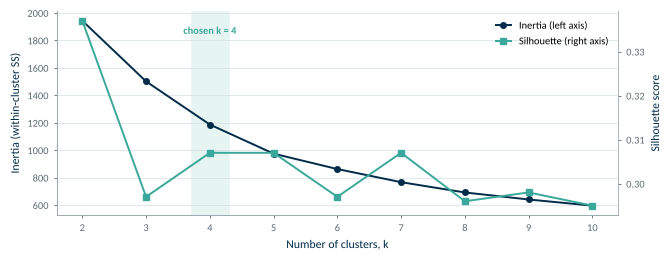

In [25]:
# Figure 6: elbow (inertia) and silhouette against k
fig, ax1 = plt.subplots(figsize=(TEXT_WIDTH, 2.5))
ax1.axvspan(K_FINAL - 0.3, K_FINAL + 0.3, color=MIST, zorder=0)
l1 = ax1.plot(kmeans_scan.index, kmeans_scan["inertia"], color=MIDNIGHT, marker="o", label="Inertia (left axis)")
ax1.set_xlabel("Number of clusters, k")
ax1.set_ylabel("Inertia (within-cluster SS)")
ax1.set_xticks(list(kmeans_scan.index))
ax2 = ax1.twinx()
l2 = ax2.plot(kmeans_scan.index, kmeans_scan["silhouette"], color=TIFFANY_DEEP, marker="s",
              label="Silhouette (right axis)")
ax2.set_ylabel("Silhouette score")
ax2.grid(False)
ax2.spines["right"].set_visible(True)
ax1.text(K_FINAL, kmeans_scan["inertia"].max() * 0.98, "chosen k = " + str(K_FINAL), ha="center", va="top",
         fontsize=7.5, color=TIFFANY_DEEP, fontweight="bold")
ax1.legend(l1 + l2, [l.get_label() for l in l1 + l2], loc="upper right")
save_figure(fig, "fig06_kmeans_elbow_silhouette.png")
plt.show()

In [26]:
kmeans = KMeans(n_clusters=K_FINAL, n_init=20, random_state=SEED)
raw_labels = kmeans.fit_predict(X)

# K-Means numbers its clusters arbitrarily, and the numbering can change with the seed. To keep the segment names,
# the colours in every chart and the text of the report stable, clusters are renumbered by what they ARE:
#   2 = best-sellers (highest median units sold), 3 = low-stock tail (lowest median stock of the rest),
#   0 = premium (higher median price of the last two), 1 = budget.
raw_profile = df.assign(raw=raw_labels).groupby("raw").agg(sold=("sold", "median"), stock=("stock_level", "median"),
                                                          price=("price", "median"))
best_sellers = raw_profile["sold"].idxmax()
low_stock = raw_profile.drop(best_sellers)["stock"].idxmin()
rest = raw_profile.drop([best_sellers, low_stock])
premium = rest["price"].idxmax()
budget = rest["price"].idxmin()
relabel = {premium: 0, budget: 1, best_sellers: 2, low_stock: 3}
df["kmeans"] = pd.Series(raw_labels, index=df.index).map(relabel)
centers = np.zeros_like(kmeans.cluster_centers_)
for old, new in relabel.items():
    centers[new] = kmeans.cluster_centers_[old]

# Centroids back in original units, which is how a business reader thinks about them
centroids_scaled = pd.DataFrame(centers, columns=FEATURES)
centroids = pd.DataFrame(scaler.inverse_transform(centers), columns=FEATURES)
centroids["price_usd"] = np.expm1(centroids["log_price"]).round(2)
centroids["units_sold"] = np.expm1(centroids["log_sold"]).round(0)
centroids["stock_level"] = centroids["stock_level"].round(1)
centroids["listings"] = df["kmeans"].value_counts().sort_index().values
print("Renumbering:", {int(k): int(v) for k, v in relabel.items()})
print(centroids[["price_usd", "units_sold", "stock_level", "listings"]])

Renumbering: {2: 0, 1: 1, 3: 2, 0: 3}
   price_usd  units_sold  stock_level  listings
0      68.86        51.0          9.9       226
1      18.62        29.0          9.8       216
2      28.93      1142.0          9.9       242
3      43.85        19.0          3.2       313


Saved: output/figures/fig07_kmeans_clusters_silhouette.png


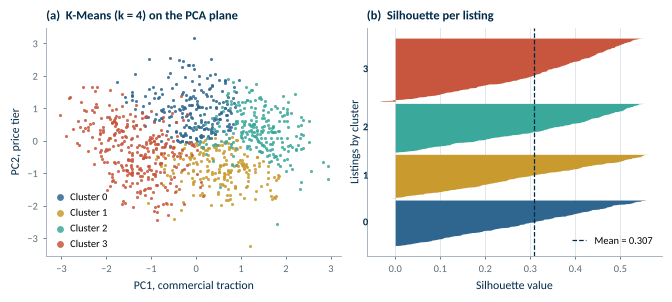

In [27]:
# Figure 7: K-Means clusters on the PCA plane, with a silhouette plot per cluster


def plot_clusters_pca(ax, labels, title, noise_label=None, colours=None):
    colours = colours or CLUSTER_COLOURS
    for lab in sorted(set(labels)):
        mask = labels == lab
        if noise_label is not None and lab == noise_label:
            ax.scatter(X_2d[mask, 0], X_2d[mask, 1], s=7, color=NOISE_GREY, marker="x", linewidths=0.6,
                       label="Noise")
        else:
            ax.scatter(X_2d[mask, 0], X_2d[mask, 1], s=5, alpha=0.85, linewidths=0,
                       color=colours[lab % len(colours)], label="Cluster " + str(lab))
    ax.set_xlabel("PC1, commercial traction")
    ax.set_ylabel("PC2, price tier")
    ax.grid(False)
    ax.set_title(title)
    ax.legend(loc="lower left", markerscale=2.2, handletextpad=0.3, borderaxespad=0.2)


fig, axes = plt.subplots(1, 2, figsize=(TEXT_WIDTH, 2.9))
plot_clusters_pca(axes[0], df["kmeans"].values, "(a)  K-Means (k = " + str(K_FINAL) + ") on the PCA plane")

sil_values = silhouette_samples(X, df["kmeans"])
y_lower = 10
for lab in range(K_FINAL):
    values = np.sort(sil_values[df["kmeans"].values == lab])
    y_upper = y_lower + len(values)
    axes[1].fill_betweenx(np.arange(y_lower, y_upper), 0, values, color=CLUSTER_COLOURS[lab], linewidth=0)
    axes[1].text(-0.06, y_lower + len(values) / 2, str(lab), color=MIDNIGHT, fontweight="bold", fontsize=7.5,
                 ha="right", va="center")
    y_lower = y_upper + 10
axes[1].axvline(sil_values.mean(), color=MIDNIGHT, linestyle="--", linewidth=0.9,
                label="Mean = " + str(round(sil_values.mean(), 3)))
axes[1].set_xlabel("Silhouette value")
axes[1].set_ylabel("Listings by cluster")
axes[1].set_yticks([])
axes[1].grid(axis="y", visible=False)
axes[1].grid(axis="x", visible=True)
panel(axes[1], "b", "Silhouette per listing")
axes[1].legend(loc="lower right")
save_figure(fig, "fig07_kmeans_clusters_silhouette.png")
plt.show()

## 7. Hierarchical clustering

Agglomerative clustering starts with every listing as its own cluster and merges the closest pair step by step. How "closest" is measured is the **linkage**. Following Lesson 9, I compare single, complete, average and Ward linkage on the same Euclidean distances. The **cophenetic correlation** says how faithfully each dendrogram preserves the original pairwise distances (closer to 1 is better).

In [28]:
linkage_methods = ["single", "complete", "average", "ward"]
distances = pdist(X)
linkage_results = {}
linkage_rows = []
for method in linkage_methods:
    Z = linkage(X, method=method)
    linkage_results[method] = Z
    coph_corr, _ = cophenet(Z, distances)
    labels_h = fcluster(Z, t=K_FINAL, criterion="maxclust")
    sizes = np.bincount(labels_h)[1:]
    linkage_rows.append({
        "linkage": method,
        "cophenetic_corr": round(coph_corr, 3),
        "silhouette_at_k": round(silhouette_score(X, labels_h), 3) if len(set(labels_h)) > 1 else np.nan,
        "cluster_sizes": "/".join(str(s) for s in sorted(sizes, reverse=True)),
    })
linkage_table = pd.DataFrame(linkage_rows).set_index("linkage")
save_table(linkage_table, "table08_linkage_comparison.csv")
linkage_table

Saved: output/tables/table08_linkage_comparison.csv


,cophenetic_corr,silhouette_at_k,cluster_sizes
linkage,,,
single,0.362,0.217,994/1/1/1
complete,0.536,0.197,424/388/180/5
average,0.631,0.206,989/6/1/1
ward,0.579,0.253,358/237/235/167


Saved: output/figures/fig08_dendrograms_four_linkages.png


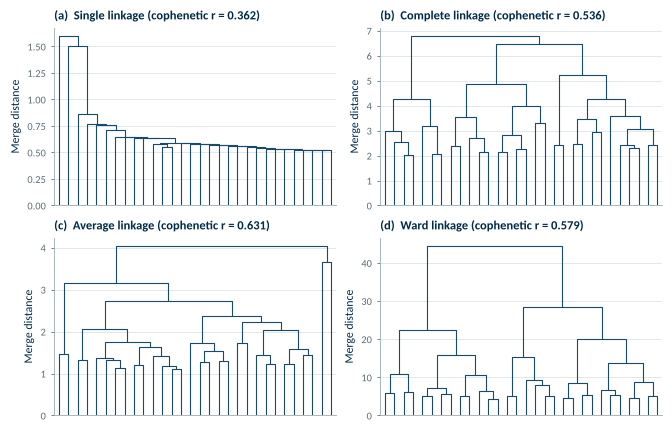

In [29]:
# Figure 8: dendrograms for the four linkages (truncated to the last 30 merges for readability)
with plt.rc_context({"lines.linewidth": 0.8}):
    fig, axes = plt.subplots(2, 2, figsize=(TEXT_WIDTH, 4.2))
    for ax, letter, method in zip(axes.ravel(), "abcd", linkage_methods):
        dendrogram(linkage_results[method], truncate_mode="lastp", p=30, ax=ax,
                   color_threshold=0, above_threshold_color=MIDNIGHT_SOFT, no_labels=True)
        panel(ax, letter, method.capitalize() + " linkage (cophenetic r = "
              + str(linkage_table.loc[method, "cophenetic_corr"]) + ")")
        ax.set_ylabel("Merge distance")
        ax.grid(axis="x", visible=False)
    save_figure(fig, "fig08_dendrograms_four_linkages.png")
    plt.show()

Single and average linkage keep the highest cophenetic correlation but produce one giant cluster plus a few tiny ones (the "chaining" effect), which is useless for segmentation. Ward linkage merges the pair that adds the least within-cluster variance, so it produces balanced, compact groups and is the natural hierarchical counterpart to K-Means. I take Ward forward.

In [30]:
# Ward: metrics across k, then the final cut at the same k as K-Means for a fair comparison
Z_ward = linkage_results["ward"]
ward_scan = []
for k in range(2, 11):
    labels_w = fcluster(Z_ward, t=k, criterion="maxclust")
    ward_scan.append({"k": k,
                      "silhouette": round(silhouette_score(X, labels_w), 3),
                      "davies_bouldin": round(davies_bouldin_score(X, labels_w), 3),
                      "calinski_harabasz": round(calinski_harabasz_score(X, labels_w), 1)})
ward_scan = pd.DataFrame(ward_scan).set_index("k")
save_table(ward_scan, "table09_ward_k_scan.csv")

# scikit-learn's AgglomerativeClustering gives the same Ward tree with 0-based labels
ward_model = AgglomerativeClustering(n_clusters=K_FINAL, linkage="ward")
df["ward"] = ward_model.fit_predict(X)
print("Ward cluster sizes:", np.bincount(df["ward"]))
print("Agreement with K-Means (Adjusted Rand Index):", round(adjusted_rand_score(df["kmeans"], df["ward"]), 3))
ward_scan

Saved: output/tables/table09_ward_k_scan.csv
Ward cluster sizes: [358 237 235 167]
Agreement with K-Means (Adjusted Rand Index): 0.408


,silhouette,davies_bouldin,calinski_harabasz
k,,,
2,0.324,1.276,488.6
3,0.276,1.265,430.9
4,0.253,1.257,402.9
5,0.241,1.159,399.3
6,0.255,1.137,382.1
7,0.244,1.087,381.0
8,0.248,1.126,381.1
9,0.244,1.153,369.5
10,0.251,1.117,363.7


Saved: output/figures/fig09_ward_dendrogram_cut.png


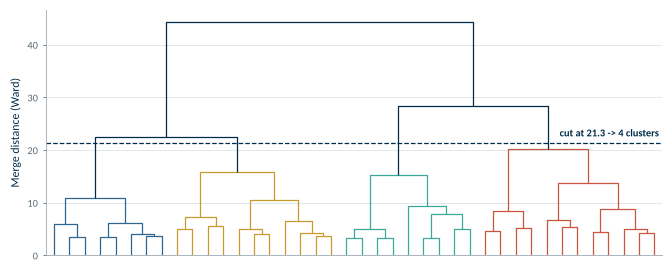

In [31]:
# Figure 9: Ward dendrogram with the cut that gives K_FINAL clusters
cut_height = (Z_ward[-K_FINAL, 2] + Z_ward[-K_FINAL + 1, 2]) / 2
set_link_color_palette([CLUSTER_COLOURS[0], CLUSTER_COLOURS[1], CLUSTER_COLOURS[2], CLUSTER_COLOURS[3]])
with plt.rc_context({"lines.linewidth": 0.9}):
    fig, ax = plt.subplots(figsize=(TEXT_WIDTH, 2.6))
    dendrogram(Z_ward, truncate_mode="lastp", p=40, ax=ax, color_threshold=cut_height,
               above_threshold_color=MIDNIGHT, no_labels=True)
    ax.axhline(cut_height, color=MIDNIGHT, linestyle="--", linewidth=0.9)
    ax.text(ax.get_xlim()[1] * 0.995, cut_height + 0.8, "cut at " + str(round(cut_height, 1)) + " -> "
            + str(K_FINAL) + " clusters", color=MIDNIGHT, ha="right", va="bottom", fontsize=7.5, fontweight="bold")
    ax.set_ylabel("Merge distance (Ward)")
    ax.grid(axis="x", visible=False)
    save_figure(fig, "fig09_ward_dendrogram_cut.png")
    plt.show()
set_link_color_palette(None)

## 8. DBSCAN

DBSCAN groups points that sit in dense regions and labels isolated points as **noise** (-1). It does not need *k*, but needs two settings: `eps` (the neighbourhood radius) and `min_samples` (how many neighbours make a point "core"). A common starting rule is `min_samples` = 2 x number of features = 6, and `eps` near the "knee" of the sorted distance to each point's *min_samples*-th nearest neighbour.

Saved: output/figures/fig10_dbscan_k_distance.png


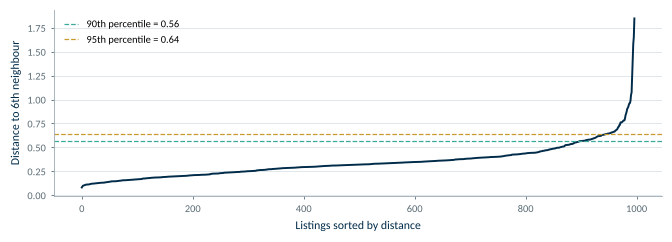

In [32]:
MIN_SAMPLES = 2 * len(FEATURES)
neighbours = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(X)
dist_k, _ = neighbours.kneighbors(X)
k_distance = np.sort(dist_k[:, -1])

# Figure 10: k-distance plot used to pick eps
fig, ax = plt.subplots(figsize=(TEXT_WIDTH, 2.3))
ax.plot(k_distance, color=MIDNIGHT)
for q, colour in [(0.90, TIFFANY_DEEP), (0.95, "#C99A2E")]:
    ax.axhline(np.quantile(k_distance, q), color=colour, linestyle="--", linewidth=0.9,
               label=str(int(q * 100)) + "th percentile = " + str(round(np.quantile(k_distance, q), 2)))
ax.set_xlabel("Listings sorted by distance")
ax.set_ylabel("Distance to " + str(MIN_SAMPLES) + "th neighbour")
ax.legend(loc="upper left")
save_figure(fig, "fig10_dbscan_k_distance.png")
plt.show()

In [33]:
# Grid search over eps and min_samples. Silhouette is computed on clustered points only,
# so it must be read together with the noise share and the number of clusters.
dbscan_rows = []
for eps in [0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.60, 0.70]:
    for min_s in [4, 6, 10, 15]:
        labels_d = DBSCAN(eps=eps, min_samples=min_s).fit_predict(X)
        n_clusters = len(set(labels_d)) - (1 if -1 in labels_d else 0)
        noise_share = (labels_d == -1).mean()
        mask = labels_d != -1
        sil = np.nan
        if n_clusters >= 2:
            sil = silhouette_score(X[mask], labels_d[mask])
        dbscan_rows.append({"eps": eps, "min_samples": min_s, "clusters": n_clusters,
                            "noise_pct": round(noise_share * 100, 1),
                            "silhouette_clustered": round(sil, 3) if not np.isnan(sil) else np.nan})
dbscan_grid = pd.DataFrame(dbscan_rows)
save_table(dbscan_grid.set_index(["eps", "min_samples"]), "table10_dbscan_grid.csv")
dbscan_grid.pivot(index="eps", columns="min_samples", values="clusters")

Saved: output/tables/table10_dbscan_grid.csv


min_samples,4,6,10,15
eps,,,,
0.25,34,9,6,4
0.30,19,14,5,6
0.35,11,9,5,4
0.40,6,4,3,3
0.45,3,2,3,2
0.50,1,1,3,1
0.60,1,1,1,1
0.70,1,1,1,1


In [34]:
dbscan_grid.pivot(index="eps", columns="min_samples", values="noise_pct")

min_samples,4,6,10,15
eps,,,,
0.25,44.1,60.9,75.3,88.6
0.30,25.7,40.2,60.8,75.8
0.35,13.3,22.9,42.7,61.0
0.40,8.3,14.3,29.4,45.5
0.45,6.2,8.9,18.6,32.2
0.50,4.4,6.8,12.0,22.7
0.60,1.5,2.5,4.7,8.3
0.70,0.8,1.0,1.3,3.0


In [35]:
EPS_FINAL = 0.45
dbscan = DBSCAN(eps=EPS_FINAL, min_samples=MIN_SAMPLES)
df["dbscan"] = dbscan.fit_predict(X)
print("DBSCAN eps =", EPS_FINAL, "min_samples =", MIN_SAMPLES)
print(df["dbscan"].value_counts().sort_index())

# What do the noise points look like?  (They are the listings DBSCAN considers unusual.)
noise_profile = df.groupby(df["dbscan"] == -1)[["price", "sold", "stock_level"]].median()
noise_profile.index = ["clustered", "noise"]
noise_profile

DBSCAN eps = 0.45 min_samples = 6
dbscan
-1     89
 0    904
 1      4
Name: count, dtype: int64


,price,sold,stock_level
clustered,35.99,45.5,9.0
noise,26.11,163.0,5.0


Saved: output/figures/fig11_dbscan_clusters.png


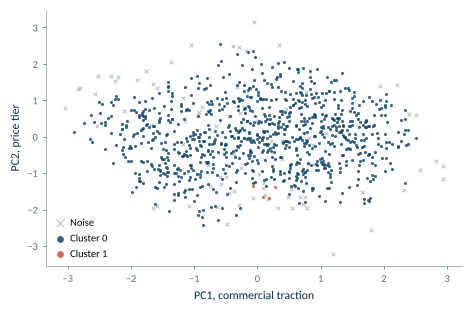

In [36]:
# Figure 11: DBSCAN result on the PCA plane
fig, ax = plt.subplots(figsize=(NARROW, 3.0))
plot_clusters_pca(ax, df["dbscan"].values, "", noise_label=-1, colours=[MIDNIGHT_SOFT, "#C8553D"])
save_figure(fig, "fig11_dbscan_clusters.png")
plt.show()

**What DBSCAN tells us.** The grid (Table 10) shows only two kinds of outcome. With a small `eps`, DBSCAN breaks the data into many tiny groups and labels 40% to 90% of listings as noise. With a larger `eps`, almost everything joins one big cluster. The chosen setting (`eps` = 0.45, `min_samples` = 6, close to the 90th percentile of the k-distance curve) is the last point before everything merges: one main cluster with 90% of listings, one very small group, and 8.9% noise.

This is a finding in itself: the listings do **not** contain separate dense regions with empty space between them, which is the structure DBSCAN is designed to find. The listings it calls noise are mostly the extreme cases (very high sales, very high price, or very low stock), so DBSCAN works well as an **anomaly flag** but not as a segmentation tool for this catalogue.

## 9. HDBSCAN

HDBSCAN (Campello, Moulavi and Sander, 2013; McInnes, Healy and Astels, 2017) is the hierarchical successor to DBSCAN and has been part of scikit-learn since version 1.3 (2023). Instead of one fixed `eps`, it builds a hierarchy over **all** density levels and keeps the clusters that persist the longest, so it can find clusters of different densities. It needs two settings: `min_cluster_size` (the smallest group worth calling a cluster) and `min_samples` (how conservative the density estimate is).

This is a direct test of Section 8: if DBSCAN failed only because no single `eps` suits every region of the data, HDBSCAN should find clear segments.

In [37]:
# Grid over both settings. min_samples = 6 matches DBSCAN, so the two density methods are comparable.
hdbscan_rows = []
for mcs in [10, 20, 30, 50, 100]:
    for min_s in [3, 6, 10]:
        labels_h = HDBSCAN(min_cluster_size=mcs, min_samples=min_s).fit_predict(X)
        n_clusters = len(set(labels_h)) - (1 if -1 in labels_h else 0)
        mask = labels_h != -1
        sil = silhouette_score(X[mask], labels_h[mask]) if n_clusters >= 2 else np.nan
        hdbscan_rows.append({"min_cluster_size": mcs, "min_samples": min_s, "clusters": n_clusters,
                             "noise_pct": round((~mask).mean() * 100, 1),
                             "silhouette_clustered": round(sil, 3) if not np.isnan(sil) else np.nan})
hdbscan_grid = pd.DataFrame(hdbscan_rows)
save_table(hdbscan_grid.set_index(["min_cluster_size", "min_samples"]), "table15_hdbscan_grid.csv")
hdbscan_grid.pivot(index="min_cluster_size", columns="min_samples", values="noise_pct")

Saved: output/tables/table15_hdbscan_grid.csv


min_samples,3,6,10
min_cluster_size,,,
10,6.2,49.0,52.3
20,39.7,47.0,52.3
30,42.4,47.0,52.3
50,35.3,47.0,52.3
100,35.3,47.0,52.3


In [38]:
MIN_CLUSTER_SIZE = 30   # about 3% of listings: the smallest group worth its own business action
hdbscan = HDBSCAN(min_cluster_size=MIN_CLUSTER_SIZE, min_samples=MIN_SAMPLES)
df["hdbscan"] = hdbscan.fit_predict(X)
df["hdbscan_strength"] = hdbscan.probabilities_   # membership strength (0 = noise, 1 = cluster core)
print("HDBSCAN min_cluster_size =", MIN_CLUSTER_SIZE, "min_samples =", MIN_SAMPLES)
print(df["hdbscan"].value_counts().sort_index())

# Profile of each HDBSCAN group. The key column is the share of listings sitting on the stock ceiling
# (11 = "More than 10 available"), which is where the marketplace censors stock.
hdbscan_profile = df.groupby("hdbscan").agg(
    listings=("price", "size"),
    median_price=("price", "median"),
    median_units_sold=("sold", "median"),
    median_stock_level=("stock_level", "median"),
    pct_at_stock_ceiling=("stock_level", lambda s: round((s == 11).mean() * 100, 1)),
)
hdbscan_profile.index = ["Noise" if i == -1 else "Cluster " + str(i) for i in hdbscan_profile.index]
save_table(hdbscan_profile, "table16_hdbscan_profile.csv")
print("Share of all listings at the stock ceiling:", round((df["stock_level"] == 11).mean() * 100, 1), "%")
hdbscan_profile

HDBSCAN min_cluster_size = 30 min_samples = 6
hdbscan
-1    469
 0    393
 1    135
Name: count, dtype: int64
Saved: output/tables/table16_hdbscan_profile.csv
Share of all listings at the stock ceiling: 41.5 %


,listings,median_price,median_units_sold,median_stock_level,pct_at_stock_ceiling
Noise,469,38.95,51.0,7.0,13.6
Cluster 0,393,29.99,116.0,11.0,89.1
Cluster 1,135,39.99,18.0,3.0,0.0


In [39]:
# Robustness: is the result produced by ties on the integer stock scale, or by the stock feature at all?
rng = np.random.default_rng(SEED)
jitter_runs = []
for run in range(10):
    jittered = df[FEATURES].copy()
    jittered["stock_level"] = jittered["stock_level"] + rng.uniform(-0.5, 0.5, len(df))   # break the ties
    lab = HDBSCAN(min_cluster_size=MIN_CLUSTER_SIZE, min_samples=MIN_SAMPLES).fit_predict(
        StandardScaler().fit_transform(jittered))
    jitter_runs.append({"clusters": len(set(lab)) - (1 if -1 in lab else 0), "noise_pct": (lab == -1).mean() * 100})
jitter_runs = pd.DataFrame(jitter_runs)
lab_no_stock = HDBSCAN(min_cluster_size=MIN_CLUSTER_SIZE, min_samples=MIN_SAMPLES).fit_predict(
    StandardScaler().fit_transform(df[["log_price", "log_sold"]]))
print("Stock jittered by +/-0.5 (10 runs): clusters", sorted(jitter_runs["clusters"].unique()),
      "| mean noise", round(jitter_runs["noise_pct"].mean(), 1), "%")
print("Price and sales only: clusters", len(set(lab_no_stock)) - (1 if -1 in lab_no_stock else 0),
      "| noise", round((lab_no_stock == -1).mean() * 100, 1), "%")

Stock jittered by +/-0.5 (10 runs): clusters [np.int64(2), np.int64(3)] | mean noise 50.4 %
Price and sales only: clusters 2 | noise 38.0 %


Saved: output/figures/fig18_hdbscan.png


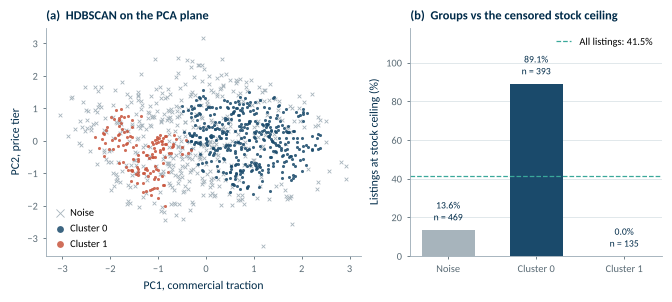

In [40]:
# Figure 18: HDBSCAN on the PCA plane, and how its clusters line up with the stock ceiling
fig, axes = plt.subplots(1, 2, figsize=(TEXT_WIDTH, 2.9), gridspec_kw={"width_ratios": [1.25, 1]})
plot_clusters_pca(axes[0], df["hdbscan"].values, "(a)  HDBSCAN on the PCA plane", noise_label=-1,
                  colours=[MIDNIGHT_SOFT, "#C8553D"])
ceiling = hdbscan_profile["pct_at_stock_ceiling"]
bar_colours = [NOISE_GREY if name == "Noise" else [MIDNIGHT_SOFT, "#C8553D"][int(name.split()[-1])]
               for name in ceiling.index]
bars = axes[1].bar(ceiling.index, ceiling.values, color=bar_colours, width=0.6)
overall = (df["stock_level"] == 11).mean() * 100
axes[1].axhline(overall, color=TIFFANY_DEEP, linestyle="--", linewidth=0.9,
                label="All listings: " + str(round(overall, 1)) + "%")
for bar, v, n in zip(bars, ceiling.values, hdbscan_profile["listings"].values):
    axes[1].text(bar.get_x() + bar.get_width() / 2, v + 3, str(v) + "%\nn = " + str(n), ha="center", va="bottom",
                 fontsize=7, color=MIDNIGHT)
axes[1].set_ylim(0, 118)
axes[1].set_ylabel("Listings at stock ceiling (%)")
panel(axes[1], "b", "Groups vs the censored stock ceiling")
axes[1].legend(loc="upper right")
save_figure(fig, "fig18_hdbscan.png")
plt.show()

**What HDBSCAN tells us.** Across the whole grid (Table 15) HDBSCAN leaves between about 35% and 52% of listings unassigned whenever it finds more than one cluster, and with `min_samples` = 6 it returns the same answer for every `min_cluster_size` from 20 to 100: two clusters and 47% noise. The larger cluster is almost entirely made of listings at the censored stock ceiling (89% sit at 11, against 41.5% of all listings); the smaller one is a low-stock group (median 3 units). Breaking the ties on the stock scale, or removing stock altogether, still leaves roughly 40–50% of listings outside any dense region.

So the more flexible density method confirms, rather than overturns, the DBSCAN result: the catalogue has no well-separated dense segments. The densest region HDBSCAN finds is partly created by the way the marketplace records stock, which is a useful data-quality insight but not a commercial segmentation.

## 10. TabClustPFN (tabular foundation model)

TabClustPFN (Zhao et al., 2026; NeurIPS 2026) is a **prior-fitted network**: a transformer pre-trained on millions of synthetic clustering problems, in the same family as the TabPFN foundation models for tabular data. It is not fitted to this dataset at all. It reads the whole table in context and returns cluster labels, and it can also **predict the number of clusters** itself, in a single forward pass with no tuning.

That makes it a useful independent check on two choices made so far: the number of segments, and whether a modern pre-trained model finds a better partition than K-Means. I run it twice: with automatic k, and with k fixed at 4 for a like-for-like comparison. Inputs are the same three standardised features.

*Set-up note.* The model is not on PyPI, so the next cell fetches the authors' code and pretrained checkpoint (licence CC BY-NC 4.0, used here for non-commercial coursework). The code imports R's `rpy2` only to generate synthetic **pre-training** data; inference never uses it, so a placeholder module that raises an error if called is supplied when R is not installed. If the model cannot be loaded (for example offline), the cell falls back to the labels saved from the assessed run and says so.

In [41]:
import sys, subprocess, importlib, importlib.util, tempfile, time

TCP_DIR = Path(os.environ.get("TABCLUSTPFN_DIR", "TabClustPFN"))
TCP_CKPT = Path(os.environ.get("TABCLUSTPFN_CKPT", str(TCP_DIR / "tabclustpfn.ckpt")))
TCP_CKPT_ID = "1GzZBgVXwOB8y9JM89xa7ln-la6v2sUO3"           # official checkpoint (Google Drive, from the README)
TCP_SAVED = OUTPUT_DIR / "tabclustpfn_labels.csv"           # labels from the assessed run (fallback)


def ensure_rpy2_placeholder():
    # rpy2 is only used to synthesise pre-training data; inference does not call it
    try:
        importlib.import_module("rpy2.robjects")
        return
    except Exception:
        pass
    stub = Path(tempfile.gettempdir()) / "tabclustpfn_stubs" / "rpy2" / "robjects"
    stub.mkdir(parents=True, exist_ok=True)
    (stub.parent / "__init__.py").write_text("")
    (stub / "__init__.py").write_text(
        "class _Unavailable:\n"
        "    def __getattr__(self, name):\n"
        "        raise RuntimeError('rpy2/R is only needed to generate TabClustPFN pre-training data')\n"
        "    def __call__(self, *a, **k):\n"
        "        raise RuntimeError('rpy2/R is only needed to generate TabClustPFN pre-training data')\n"
        "r = _Unavailable()\nNULL = None\ndefault_converter = None\n"
        "FloatVector = IntVector = StrVector = _Unavailable()\n")
    (stub / "packages.py").write_text("from . import _Unavailable as importr\n")
    (stub / "conversion.py").write_text("from . import _Unavailable as localconverter\n")
    sys.path.insert(0, str(stub.parent.parent))


tcp_model = None
try:
    if not TCP_DIR.exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/Tianqi-Zhao/TabClustPFN.git", str(TCP_DIR)],
                       check=True)
    for package in ["torch", "einops", "transformers", "tensorboard", "psutil", "tqdm"]:
        if importlib.util.find_spec(package) is None:
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", package], check=True)
    if not TCP_CKPT.exists():
        if importlib.util.find_spec("gdown") is None:
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gdown"], check=True)
        subprocess.run([sys.executable, "-m", "gdown", TCP_CKPT_ID, "-O", str(TCP_CKPT)], check=True)
    ensure_rpy2_placeholder()
    sys.path.insert(0, str(TCP_DIR))
    import torch
    from cluster import load_model as tcp_load_model, cluster as tcp_cluster
    torch.manual_seed(SEED)
    TCP_DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
    tcp_model = tcp_load_model(str(TCP_CKPT), TCP_DEVICE)
    print("TabClustPFN loaded on", TCP_DEVICE)
except Exception as error:
    print("TabClustPFN could not be loaded here (" + type(error).__name__ + ": " + str(error)[:120] + ").")
    print("Falling back to the labels saved from the assessed run:", TCP_SAVED)


def fit_tabclustpfn(data, k=None):
    labels, k_used = tcp_cluster(tcp_model, np.asarray(data), num_clusters=k, device=TCP_DEVICE)
    return np.asarray(labels)

/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading checkpoint from: /tmp/ext/ckpt/tabclustpfn.ckpt


Model (TabClusterIMAB) loaded successfully.
TabClustPFN loaded on cpu


In [42]:
if tcp_model is not None:
    start = time.time()
    labels_auto, k_auto = tcp_cluster(tcp_model, X, num_clusters=None, device=TCP_DEVICE)
    seconds_auto = time.time() - start
    labels_k4 = fit_tabclustpfn(X, K_FINAL)
    df["tabclustpfn"] = np.asarray(labels_auto)
    df["tabclustpfn_k4"] = labels_k4
    df[["tabclustpfn", "tabclustpfn_k4"]].to_csv(TCP_SAVED, index=False)
    print("Automatic k predicted by the model:", k_auto, "| inference time:", round(seconds_auto, 1), "s")
else:
    saved = pd.read_csv(TCP_SAVED)
    df["tabclustpfn"], df["tabclustpfn_k4"] = saved["tabclustpfn"].values, saved["tabclustpfn_k4"].values
    k_auto = df["tabclustpfn"].nunique()

# Two robustness checks specific to an in-context model: does k stay the same on subsamples,
# and does the order of the rows matter?
tcp_checks = {}
if tcp_model is not None:
    rng = np.random.default_rng(SEED)
    sub_k = []
    for run in range(30):
        idx = rng.choice(len(X), size=int(0.8 * len(X)), replace=False)
        sub_k.append(tcp_cluster(tcp_model, X[idx], num_clusters=None, device=TCP_DEVICE)[1])
    perm = rng.permutation(len(X))
    shuffled = fit_tabclustpfn(X[perm])
    restored = np.empty_like(shuffled)
    restored[perm] = shuffled
    tcp_checks = {"predicted_k": int(k_auto),
                  "subsamples_with_same_k": int(sum(k == k_auto for k in sub_k)),
                  "ari_row_shuffle": round(adjusted_rand_score(df["tabclustpfn"], restored), 3)}
    print("Same k on", tcp_checks["subsamples_with_same_k"], "of 30 subsamples | ARI after shuffling rows:",
          tcp_checks["ari_row_shuffle"])

tcp_profile_rows = []
for column, variant in [("tabclustpfn", "auto k = " + str(k_auto)), ("tabclustpfn_k4", "k = " + str(K_FINAL))]:
    for lab, group in df.groupby(column):
        tcp_profile_rows.append({
            "variant": variant, "cluster": lab, "listings": len(group),
            "median_price": round(group["price"].median(), 2),
            "median_units_sold": group["sold"].median(),
            "share_of_units_sold_pct": round(group["sold"].sum() / df["sold"].sum() * 100, 1),
            "median_stock_level": group["stock_level"].median(),
            "pct_at_stock_ceiling": round((group["stock_level"] == 11).mean() * 100, 1)})
tcp_profile = pd.DataFrame(tcp_profile_rows).set_index(["variant", "cluster"])
save_table(tcp_profile, "table17_tabclustpfn.csv")
print("ARI with K-Means: auto", round(adjusted_rand_score(df["kmeans"], df["tabclustpfn"]), 3),
      "| k = 4", round(adjusted_rand_score(df["kmeans"], df["tabclustpfn_k4"]), 3))
tcp_profile

Automatic k predicted by the model: 2 | inference time: 16.7 s


Same k on 30 of 30 subsamples | ARI after shuffling rows: 1.0
Saved: output/tables/table17_tabclustpfn.csv
ARI with K-Means: auto 0.327 | k = 4 0.368


listings  median_price  median_units_sold  \
variant    cluster                                              
auto k = 2 0             410         39.00               19.5   
           1             587         32.98              150.0   
k = 4      0             150         51.99               21.0   
           1             407         28.93              129.0   
           2             299         37.99               16.0   
           3             141         41.00              539.0   

                    share_of_units_sold_pct  median_stock_level  \
variant    cluster                                                
auto k = 2 0                            6.9                 3.0   
           1                           93.1                11.0   
k = 4      0                            0.6                 8.0   
           1                           38.9                11.0   
           2                            3.2                 3.0   
           3                           57.4                 9.0   

                    pct_at_stock_ceiling  
variant    cluster                        
auto k = 2 0                         0.0  
           1                        70.5  
k = 4      0                        10.7  
           1                        97.3  
           2                         0.0  
           3                         1.4

Saved: output/figures/fig19_tabclustpfn.png


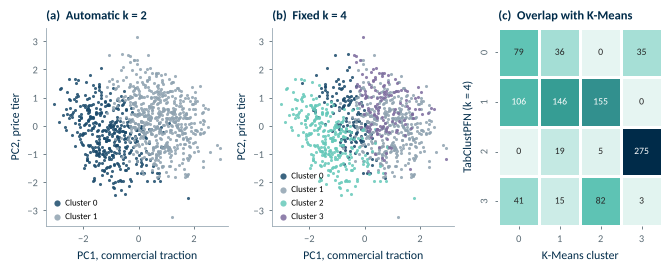

In [43]:
# Figure 19: TabClustPFN partitions on the PCA plane, and how the k = 4 version maps onto K-Means
fig, axes = plt.subplots(1, 3, figsize=(TEXT_WIDTH, 2.6), gridspec_kw={"width_ratios": [1, 1, 0.9]})
tcp_colours = [MIDNIGHT_SOFT, "#8FA3B1", TIFFANY, "#7D6B9E"]   # neutral: segment colours stay reserved for K-Means
plot_clusters_pca(axes[0], df["tabclustpfn"].values, "(a)  Automatic k = " + str(k_auto), colours=tcp_colours)
plot_clusters_pca(axes[1], df["tabclustpfn_k4"].values, "(b)  Fixed k = " + str(K_FINAL), colours=tcp_colours)
cross = pd.crosstab(df["tabclustpfn_k4"], df["kmeans"])
sns.heatmap(cross, annot=True, fmt="d", cmap=ARDEN_CMAP, cbar=False, linewidths=1, linecolor="white",
            annot_kws={"fontsize": 7}, ax=axes[2])
axes[2].set_xlabel("K-Means cluster")
axes[2].set_ylabel("TabClustPFN (k = 4)")
axes[2].grid(False)
panel(axes[2], "c", "Overlap with K-Means")
for ax in axes[:2]:
    ax.legend(loc="lower left", markerscale=2, fontsize=6.5, handletextpad=0.2, borderaxespad=0.1)
save_figure(fig, "fig19_tabclustpfn.png")
plt.show()

**What TabClustPFN tells us.** Left to choose for itself, the foundation model predicts **two** clusters, and it does so consistently: the same k on every subsample, and identical labels when the rows are shuffled. Its split is the most basic one in the catalogue, listings with thin stock against everything else; almost all of the K-Means low-stock segment falls in its smaller cluster. This is an independent confirmation, from a model that never saw this data during training, that stock position is the strongest structure in the catalogue.

Forced to four clusters it does noticeably worse than K-Means on every internal index, and one of its groups is almost entirely listings at the censored stock ceiling, the same artefact HDBSCAN found. The pre-trained model is therefore an excellent check on structure and on the choice of k, but on this small, low-dimensional table it does not beat a well-prepared K-Means for a business segmentation.

## 11. Model comparison and validation

Clustering has no "correct answer" to score against, so I combine four kinds of evidence:

1. **Internal indices**: silhouette (higher is better), Davies-Bouldin (lower is better), Calinski-Harabasz (higher is better).
2. **Stability**: re-fit on 30 random 80% subsamples and measure agreement with the full-data labels using the Adjusted Rand Index (ARI, 1 = identical grouping, 0 = chance).
3. **Sensitivity**: repeat with min-max scaling and without the top 1% of sellers.
4. **Usefulness**: cluster sizes and whether every listing gets an actionable label.

In [44]:
def internal_scores(labels, ignore_noise=False):
    labels = np.asarray(labels)
    mask = np.ones(len(labels), dtype=bool)
    if ignore_noise:
        mask = labels != -1
    return {
        "silhouette": round(silhouette_score(X[mask], labels[mask]), 3),
        "davies_bouldin": round(davies_bouldin_score(X[mask], labels[mask]), 3),
        "calinski_harabasz": round(calinski_harabasz_score(X[mask], labels[mask]), 1),
    }


def bootstrap_stability(fit_function, n_runs=30, frac=0.8):
    # Fit on the full data once, then on random subsamples, and compare labels on the shared rows
    full_labels = fit_function(X)
    rng = np.random.default_rng(SEED)
    scores = []
    for run in range(n_runs):
        idx = rng.choice(len(X), size=int(frac * len(X)), replace=False)
        sub_labels = fit_function(X[idx])
        scores.append(adjusted_rand_score(full_labels[idx], sub_labels))
    return np.mean(scores), np.std(scores)


def fit_kmeans(data):
    return KMeans(n_clusters=K_FINAL, n_init=20, random_state=SEED).fit_predict(data)


def fit_ward(data):
    return AgglomerativeClustering(n_clusters=K_FINAL, linkage="ward").fit_predict(data)


def fit_dbscan(data):
    return DBSCAN(eps=EPS_FINAL, min_samples=MIN_SAMPLES).fit_predict(data)


def fit_hdbscan(data):
    return HDBSCAN(min_cluster_size=MIN_CLUSTER_SIZE, min_samples=MIN_SAMPLES).fit_predict(data)


comparison_rows = []
for name, column, fit_function, ignore_noise in [
        ("K-Means", "kmeans", fit_kmeans, False),
        ("Hierarchical (Ward)", "ward", fit_ward, False),
        ("DBSCAN", "dbscan", fit_dbscan, True),
        ("HDBSCAN", "hdbscan", fit_hdbscan, True),
        ("TabClustPFN (auto k)", "tabclustpfn", fit_tabclustpfn if tcp_model is not None else None, False),
        ("TabClustPFN (k = 4)", "tabclustpfn_k4",
         (lambda data: fit_tabclustpfn(data, K_FINAL)) if tcp_model is not None else None, False)]:
    labels = df[column].values
    scores = internal_scores(labels, ignore_noise=ignore_noise)
    if fit_function is not None:
        stab_mean, stab_std = bootstrap_stability(fit_function)
    else:      # TabClustPFN unavailable in this environment: reuse the stability measured in the assessed run
        previous = pd.read_csv(TABLE_DIR / "table11_model_comparison.csv", index_col=0)
        stab_mean, stab_std = previous.loc[name, "stability_ARI_mean"], previous.loc[name, "stability_ARI_sd"]
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    sizes = pd.Series(labels[labels != -1]).value_counts()
    row = {"model": name, "clusters": n_clusters, "noise_pct": round((labels == -1).mean() * 100, 1)}
    row.update(scores)
    row["stability_ARI_mean"] = round(stab_mean, 3)
    row["stability_ARI_sd"] = round(stab_std, 3)
    row["smallest_cluster_pct"] = round(sizes.min() / len(labels) * 100, 1)
    row["largest_cluster_pct"] = round(sizes.max() / len(labels) * 100, 1)
    comparison_rows.append(row)

comparison = pd.DataFrame(comparison_rows).set_index("model")
save_table(comparison, "table11_model_comparison.csv")
comparison

Saved: output/tables/table11_model_comparison.csv


,clusters,noise_pct,silhouette,davies_bouldin,calinski_harabasz,stability_ARI_mean,stability_ARI_sd,smallest_cluster_pct,largest_cluster_pct
model,,,,,,,,,
K-Means,4,0.0,0.307,1.013,503.3,0.929,0.033,21.7,31.4
Hierarchical (Ward),4,0.0,0.253,1.257,402.9,0.480,0.063,16.8,35.9
DBSCAN,2,8.9,-0.014,1.172,3.5,0.749,0.068,0.4,90.7
HDBSCAN,2,47.0,0.480,0.785,476.0,0.745,0.101,13.5,39.4
TabClustPFN (auto k),2,0.0,0.326,1.261,497.6,0.967,0.022,41.1,58.9
TabClustPFN (k = 4),4,0.0,0.152,1.710,278.7,0.926,0.027,14.1,40.8


In [45]:
# Seed stability for K-Means: does the answer change with the random start?
# Reference = the run with the project seed; the other nine use seeds 0 to 8, so this is a real test of the start
seed_labels = [KMeans(n_clusters=K_FINAL, n_init=20, random_state=s).fit_predict(X) for s in [SEED] + list(range(9))]
seed_ari = [adjusted_rand_score(seed_labels[0], lab) for lab in seed_labels[1:]]
print("K-Means ARI across 10 seeds: min", round(min(seed_ari), 3), "mean", round(np.mean(seed_ari), 3))

# Sensitivity 1: min-max scaling instead of z-scores (as used in the lessons)
X_minmax = MinMaxScaler().fit_transform(df[FEATURES])
km_minmax = KMeans(n_clusters=K_FINAL, n_init=20, random_state=SEED).fit_predict(X_minmax)
print("ARI z-score vs min-max K-Means:", round(adjusted_rand_score(df["kmeans"], km_minmax), 3))

# Sensitivity 2: drop the top 1% sellers and re-fit; compare labels on the remaining rows
keep = df["sold"] < df["sold"].quantile(0.99)
X_trim = StandardScaler().fit_transform(df.loc[keep, FEATURES])
km_trim = KMeans(n_clusters=K_FINAL, n_init=20, random_state=SEED).fit_predict(X_trim)
print("ARI full vs without top 1% sellers:", round(adjusted_rand_score(df.loc[keep, "kmeans"], km_trim), 3))

sensitivity = pd.DataFrame({
    "check": ["K-Means across 10 seeds (mean ARI)", "z-score vs min-max scaling (ARI)", "with vs without top 1% sellers (ARI)"],
    "ARI": [round(np.mean(seed_ari), 3),
            round(adjusted_rand_score(df["kmeans"], km_minmax), 3),
            round(adjusted_rand_score(df.loc[keep, "kmeans"], km_trim), 3)],
}).set_index("check")
save_table(sensitivity, "table12_sensitivity_checks.csv")
sensitivity

K-Means ARI across 10 seeds: min 0.948 mean 0.964
ARI z-score vs min-max K-Means: 0.494
ARI full vs without top 1% sellers: 0.943
Saved: output/tables/table12_sensitivity_checks.csv


,ARI
check,
K-Means across 10 seeds (mean ARI),0.964
z-score vs min-max scaling (ARI),0.494
with vs without top 1% sellers (ARI),0.943


Saved: output/figures/fig12_model_comparison.png


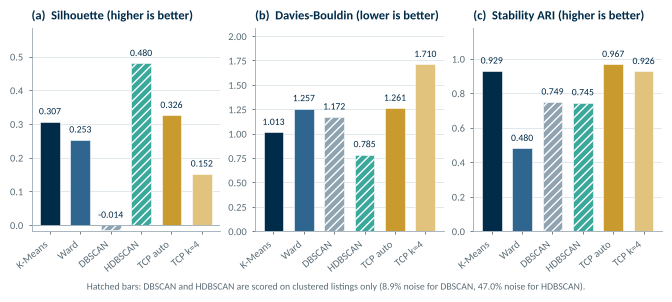

In [46]:
# Figure 12: side-by-side comparison of the models
metrics_to_plot = [("silhouette", "Silhouette (higher is better)"),
                   ("davies_bouldin", "Davies-Bouldin (lower is better)"),
                   ("stability_ARI_mean", "Stability ARI (higher is better)")]
short = {"Hierarchical (Ward)": "Ward", "TabClustPFN (auto k)": "TCP auto", "TabClustPFN (k = 4)": "TCP k=4"}
fig, axes = plt.subplots(1, 3, figsize=(TEXT_WIDTH, 2.9))
for ax, letter, (metric, label) in zip(axes, "abc", metrics_to_plot):
    values = comparison[metric]
    names = [short.get(m, m) for m in comparison.index]
    bars = ax.bar(names, values, color=[MODEL_COLOURS[m] for m in comparison.index], width=0.65,
                  edgecolor="white", linewidth=0.4)
    for bar, m in zip(bars, comparison.index):
        if comparison.loc[m, "noise_pct"] > 0:      # density models: scored on clustered points only
            bar.set_hatch("////")
    for bar, v in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width() / 2, max(v, 0) + max(values) * 0.03, format(v, ".3f"), ha="center",
                va="bottom", color=MIDNIGHT, fontsize=7)
    panel(ax, letter, label)
    ax.set_ylim(min(0, values.min() * 1.3), max(values) * 1.22)
    ax.axhline(0, color="#9AAAB4", linewidth=0.6)
    plt.setp(ax.get_xticklabels(), rotation=40, ha="right")
fig.supxlabel("Hatched bars: DBSCAN and HDBSCAN are scored on clustered listings only ("
              + ", ".join(str(comparison.loc[m, "noise_pct"]) + "% noise for " + m
                          for m in comparison.index if comparison.loc[m, "noise_pct"] > 0) + ").",
              fontsize=7, color=MUTE)
save_figure(fig, "fig12_model_comparison.png")
plt.show()

**Reading the comparison.**

- **K-Means** has the best silhouette (0.307), the lowest Davies-Bouldin (1.013) and the highest Calinski-Harabasz (503.3) of the four-segment solutions that cover every listing (K-Means, Ward and TabClustPFN at k = 4). More importantly, it is **stable**: the grouping barely changes when 20% of the listings are removed (mean ARI 0.93), when the random seed changes (0.96) or when the top 1% of sellers are dropped (0.94).
- **Ward** produces similar-sized groups but scores lower on every index, and its grouping is **unstable** under resampling (ARI 0.48). Because every merge in a hierarchy is final, a few changed points early on can reshape the whole tree.
- **DBSCAN** does not segment this data (see Section 8). Its silhouette on clustered points is about zero, and one cluster holds 91% of listings.
- **TabClustPFN** with automatic k is the most stable model of all and confirms the basic low-stock split, but at k = 4 it trails K-Means on every index (Section 10).
- **HDBSCAN** shows the highest silhouette (0.48) and lowest Davies-Bouldin (0.79), but these are computed on the 53% of listings it keeps: dropping the hardest 47% as noise makes any index look better. Its larger cluster is the stock-ceiling pile-up (Section 9), so it is a data-quality finding rather than a segmentation.
- **Scaling matters.** Swapping z-scores for min-max scaling changes the K-Means grouping noticeably (ARI 0.49). Min-max gives `stock_level`, which only takes values 1 to 11, a different weight from the two log measures. I keep z-scores because they give each feature equal variance, but this is recorded as a limitation: the segment boundaries depend partly on how the features are weighted.

None of the silhouette values are high. A score around 0.3 means the clusters are real but overlapping regions of a continuum, so the segments should be treated as useful groupings for decisions, not as natural categories.

## 12. Final model and cluster profiles
13. Report diagrams

**Final model: K-Means with k = 4.** On technical grounds it has the best internal scores and by far the best stability. On business grounds it puts every listing into a segment (no "noise" bucket to explain), its centroids can be read directly as a typical price, sales level and stock position, and new listings can be assigned to the nearest centroid instantly, which suits a fast-growing catalogue. Ward is kept as a cross-check (ARI with K-Means is reported in the ledger), DBSCAN as an anomaly flag and HDBSCAN as a data-quality probe.

The profile describes each cluster in business units: typical price, typical units sold, stock position, share of all units sold, product-type mix, main brands and where listings ship from.

In [47]:
FINAL = "kmeans"
groups = df.groupby(FINAL)
profile = pd.DataFrame({
    "listings": groups.size(),
    "share_of_listings_pct": (groups.size() / len(df) * 100).round(1),
    "median_price_usd": groups["price"].median().round(2),
    "median_units_sold": groups["sold"].median().round(0),
    "mean_units_sold": groups["sold"].mean().round(0),
    "share_of_units_sold_pct": (groups["sold"].sum() / df["sold"].sum() * 100).round(1),
    "median_stock_level": groups["stock_level"].median(),
    "pct_last_one": groups["stock_level"].apply(lambda s: (s == 1).mean() * 100).round(1),
    "pct_ships_from_us": (groups["ships_from_us"].mean() * 100).round(1),
    "pct_at_stock_ceiling": groups["stock_level"].apply(lambda s: (s == 11).mean() * 100).round(1),
    "share_of_revenue_proxy_pct": ((df["price"] * df["sold"]).groupby(df[FINAL]).sum()
                                   / (df["price"] * df["sold"]).sum() * 100).round(1),
    "median_days_since_update": groups["days_since_update"].median().round(1),
})
top_type = groups["product_type"].agg(lambda s: s.value_counts().index[0])
top_type_share = groups["product_type"].agg(lambda s: round(s.value_counts(normalize=True).iloc[0] * 100, 1))
profile["top_product_type"] = top_type + " (" + top_type_share.astype(str) + "%)"
profile["top_brands"] = groups["brand"].agg(lambda s: ", ".join(s.value_counts().index[:3]))
save_table(profile, "table13_cluster_profiles.csv")
profile.T

Saved: output/tables/table13_cluster_profiles.csv


kmeans,0,1,2,3
listings,226,216,242,313
share_of_listings_pct,22.7,21.7,24.3,31.4
median_price_usd,67.14,18.1,29.76,40.95
median_units_sold,42.0,30.0,918.0,16.0
mean_units_sold,129.0,61.0,2883.0,95.0
share_of_units_sold_pct,3.8,1.7,90.7,3.8
median_stock_level,11.0,11.0,11.0,3.0
pct_last_one,0.0,0.0,0.4,14.7
pct_ships_from_us,84.1,93.1,99.6,88.5
pct_at_stock_ceiling,54.0,63.4,64.0,0.0


In [48]:
# Product-type mix per cluster (row percentages)
type_mix = pd.crosstab(df[FINAL], df["product_type"], normalize="index").mul(100).round(1)
save_table(type_mix, "table14_product_type_mix.csv")
type_mix

Saved: output/tables/table14_product_type_mix.csv


product_type,Cologne,Eau de Parfum,Eau de Toilette,Generic fragrance,Other,Parfum / Extrait
kmeans,,,,,,
0,3.1,43.8,42.0,3.5,1.3,6.2
1,6.9,31.0,37.0,15.3,8.3,1.4
2,7.9,18.2,67.4,2.5,3.3,0.8
3,8.9,32.6,38.7,12.8,3.8,3.2


Saved: output/figures/fig13_cluster_profiles.png


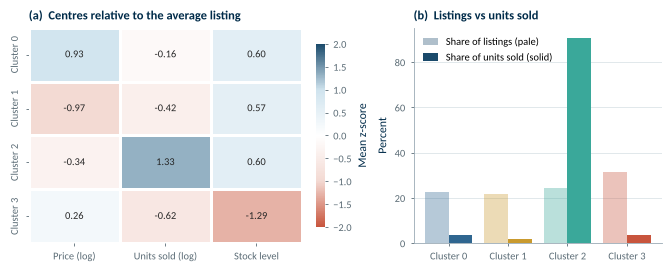

In [49]:
# Figure 13: cluster profiles as standardised feature means (how each cluster differs from the average listing)
z_profile = pd.DataFrame(X, columns=["Price (log)", "Units sold (log)", "Stock level"])
z_profile[FINAL] = df[FINAL].values
z_means = z_profile.groupby(FINAL).mean()
z_means.index = ["Cluster " + str(i) for i in z_means.index]

fig, axes = plt.subplots(1, 2, figsize=(TEXT_WIDTH, 2.6), gridspec_kw={"width_ratios": [1.1, 1]})
sns.heatmap(z_means, annot=True, fmt=".2f", cmap=ARDEN_DIVERGING, center=0, vmin=-2, vmax=2,
            linewidths=1, linecolor="white", annot_kws={"fontsize": 7.5},
            cbar_kws={"label": "Mean z-score", "shrink": 0.85}, ax=axes[0])
axes[0].grid(False)
axes[0].set_ylabel("")
panel(axes[0], "a", "Centres relative to the average listing")

share = profile[["share_of_listings_pct", "share_of_units_sold_pct"]].copy()
x_pos = np.arange(len(share))
for i, lab in enumerate(share.index):
    axes[1].bar(i - 0.2, share.loc[lab, "share_of_listings_pct"], width=0.4, color=CLUSTER_COLOURS[lab], alpha=0.35)
    axes[1].bar(i + 0.2, share.loc[lab, "share_of_units_sold_pct"], width=0.4, color=CLUSTER_COLOURS[lab])
from matplotlib.patches import Patch
axes[1].legend(handles=[Patch(facecolor=MIDNIGHT_SOFT, alpha=0.35, label="Share of listings (pale)"),
                        Patch(facecolor=MIDNIGHT_SOFT, label="Share of units sold (solid)")], loc="upper left")
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(["Cluster " + str(i) for i in share.index])
axes[1].set_ylabel("Percent")
panel(axes[1], "b", "Listings vs units sold")
save_figure(fig, "fig13_cluster_profiles.png")
plt.show()

Saved: output/figures/fig14_cluster_distributions.png


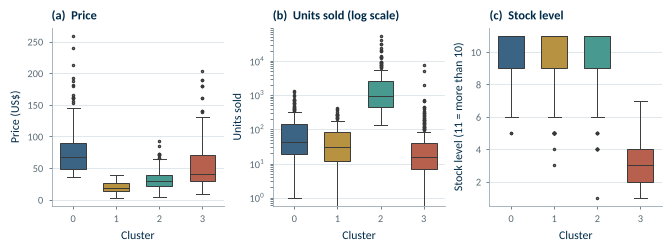

In [50]:
# Figure 14: distributions of price, units sold and stock inside each cluster
fig, axes = plt.subplots(1, 3, figsize=(TEXT_WIDTH, 2.4))
order = sorted(df[FINAL].unique())
palette = [CLUSTER_COLOURS[i] for i in order]
box_style = dict(order=order, palette=palette, hue=FINAL, legend=False, fliersize=1.5, linewidth=0.7, width=0.6)
sns.boxplot(data=df, x=FINAL, y="price", ax=axes[0], **box_style)
panel(axes[0], "a", "Price")
axes[0].set_ylabel("Price (US$)")
sns.boxplot(data=df, x=FINAL, y="sold", ax=axes[1], **box_style)
axes[1].set_yscale("log")
panel(axes[1], "b", "Units sold (log scale)")
axes[1].set_ylabel("Units sold")
sns.boxplot(data=df, x=FINAL, y="stock_level", ax=axes[2], **box_style)
panel(axes[2], "c", "Stock level")
axes[2].set_ylabel("Stock level (11 = more than 10)")
for ax in axes:
    ax.set_xlabel("Cluster")
save_figure(fig, "fig14_cluster_distributions.png")
plt.show()

**The four segments** (numbers from Table 13):

| Cluster | Working name | Typical listing | What stands out |
|---|---|---|---|
| 2 | **Best-sellers** | about \$30, roughly 920 units sold, deep stock | 24% of listings but **91% of all units sold**; mostly Eau de Toilette (67%); almost all ship from the US |
| 0 | **Premium, slow-moving** | about \$67, around 40 sold, deep stock | Highest prices; designer Eau de Parfum (Armani, Paco Rabanne, YSL); stock is plentiful but turnover is low |
| 1 | **Budget, slow-moving** | about \$18, around 30 sold, deep stock | Cheapest listings; many unbranded or dupe-style products; low sales despite low price |
| 3 | **Low-stock** | about \$41, around 16 sold, about 3 units left | The only segment with thin stock (15% show "Last One"); these listings are close to disappearing |

These names describe the data; the business reasons behind each pattern (for example, *why* budget items sell slowly) are hypotheses to test, not findings.

## 13. Segment rules: how much of the segmentation is just thresholds?

A clustering is only useful if the business can run it. Two quick checks show how much structure K-Means really found. First, how well does a **single rule** on sales recover the best-sellers? Second, how well does a small **decision tree** reproduce all four segments from the raw price, sales and stock? The tree is not a new model of the data: it is a readable description of the K-Means result, scored by cross-validated accuracy (accuracy is a valid measure here because the K-Means labels are the thing being reproduced, not a ground truth).

In [51]:
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.model_selection import cross_val_score, StratifiedKFold

RAW_FEATURES = ["price", "sold", "stock_level"]
folds = StratifiedKFold(5, shuffle=True, random_state=SEED)
rule_rows = []
for depth in [2, 3, 4]:
    tree = DecisionTreeClassifier(max_depth=depth, random_state=SEED)
    accuracy = cross_val_score(tree, df[RAW_FEATURES], df["kmeans"], cv=folds).mean()
    rule_rows.append({"max_depth": depth, "rules (leaves)": tree.fit(df[RAW_FEATURES], df["kmeans"]).get_n_leaves(),
                      "cv_accuracy": round(accuracy, 3)})
segment_rules = pd.DataFrame(rule_rows).set_index("max_depth")
save_table(segment_rules, "table18_segment_rules.csv")

# The depth-3 tree as readable rules (class 0 premium, 1 budget, 2 best-sellers, 3 low-stock tail)
readable_tree = DecisionTreeClassifier(max_depth=3, random_state=SEED).fit(df[RAW_FEATURES], df["kmeans"])
print(export_text(readable_tree, feature_names=RAW_FEATURES))
segment_rules

Saved: output/tables/table18_segment_rules.csv
|--- stock_level <= 6.50
|   |--- sold <= 353.50
|   |   |--- price <= 16.68
|   |   |   |--- class: 1
|   |   |--- price >  16.68
|   |   |   |--- class: 3
|   |--- sold >  353.50
|   |   |--- stock_level <= 3.50
|   |   |   |--- class: 3
|   |   |--- stock_level >  3.50
|   |   |   |--- class: 2
|--- stock_level >  6.50
|   |--- sold <= 167.00
|   |   |--- price <= 36.82
|   |   |   |--- class: 1
|   |   |--- price >  36.82
|   |   |   |--- class: 0
|   |--- sold >  167.00
|   |   |--- price <= 59.05
|   |   |   |--- class: 2
|   |   |--- price >  59.05
|   |   |   |--- class: 0



,rules (leaves),cv_accuracy
max_depth,,
2,4,0.712
3,8,0.898
4,16,0.919


In [52]:
# One line for the most valuable segment: "sold at least X units" versus the K-Means best-sellers
is_best_seller = df["kmeans"] == 2
best_rows = []
for cutoff in [200, 300, 500]:
    flagged = df["sold"] >= cutoff
    best_rows.append({"rule": "sold >= " + str(cutoff), "listings_flagged": int(flagged.sum()),
                      "precision_pct": round((flagged & is_best_seller).sum() / flagged.sum() * 100, 1),
                      "recall_pct": round((flagged & is_best_seller).sum() / is_best_seller.sum() * 100, 1)})
best_seller_rule = pd.DataFrame(best_rows).set_index("rule")
save_table(best_seller_rule, "table19_best_seller_rule.csv")

# How concentrated is demand in the first place?
units_sorted = df["sold"].sort_values(ascending=False)
print("Top 10% of listings sell", round(units_sorted.head(int(len(df) * 0.10)).sum() / units_sorted.sum() * 100, 1),
      "% of units; top 25% sell", round(units_sorted.head(int(len(df) * 0.25)).sum() / units_sorted.sum() * 100, 1), "%")
best_seller_rule

Saved: output/tables/table19_best_seller_rule.csv
Top 10% of listings sell 81.7 % of units; top 25% sell 94.3 %


,listings_flagged,precision_pct,recall_pct
rule,,,
sold >= 200,310,75.2,96.3
sold >= 300,255,82.7,87.2
sold >= 500,190,90.0,70.7


**What the checks show.** Demand is extremely concentrated: a quarter of the listings sell about 94% of the units, so a one-line sales rule already finds most of the best-sellers (a cut-off of 300 units recovers 87% of them, with 83% precision). The clustering therefore adds the least for the head of the catalogue. Where it earns its keep is the remaining three quarters of listings, which the tree separates by stock and price: a depth-3 tree with eight leaves (seven decisions) reproduces the K-Means segments with about 90% cross-validated accuracy. The segments are, to a good approximation, *stock thin or deep, then sales high or low, then price high or low*. That is a strength, not a weakness: the segments can be run in a spreadsheet or a database query, with K-Means as the way the thresholds were found and shown to hang together.

## 14. Report diagrams

Three figures in the report are diagrams rather than data plots: the workflow, the data-preparation flow and the segment-action summary. They are drawn here, with the same palette, type sizes and print size as every other figure, so that **all visuals come from this notebook**. The segment-action chart reads the profile table built above.

In [53]:
from matplotlib.patches import FancyBboxPatch


def diagram_canvas(height):
    # A blank drawing area measured in inches, so positions below are physical positions on the printed page
    fig = plt.figure(figsize=(TEXT_WIDTH, height), layout="none")
    ax = fig.add_axes([0, 0, 1, 1])
    ax.set_xlim(0, TEXT_WIDTH)
    ax.set_ylim(0, height)
    ax.axis("off")
    return fig, ax


def diagram_box(ax, x, y, w, h, text, fc="white", ec=GRID, tc=MIDNIGHT, bold=False, size=7.5, accent=None, lw=0.7):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0,rounding_size=0.05", fc=fc, ec=ec, lw=lw))
    if accent:
        ax.add_patch(FancyBboxPatch((x, y), 0.05, h, boxstyle="square,pad=0", fc=accent, ec="none"))
    ax.text(x + w / 2 + (0.025 if accent else 0), y + h / 2, text, ha="center", va="center", color=tc, fontsize=size,
            fontweight="bold" if bold else "normal", linespacing=1.15)


def diagram_arrow(ax, x1, y1, x2, y2, color=MIDNIGHT_SOFT, lw=0.9):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle="-|>", color=color, lw=lw, mutation_scale=7, shrinkA=0, shrinkB=0))


def diagram_line(ax, xs, ys, color=MIDNIGHT_SOFT, lw=0.9):
    ax.plot(xs, ys, color=color, lw=lw, solid_capstyle="butt")

Saved: output/figures/fig15_workflow.png


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:158: UserWarning: There are no gridspecs with layoutgrids. Possibly did not call parent GridSpec with the "figure" keyword
  fig.canvas.print_figure(bytes_io, **kw)


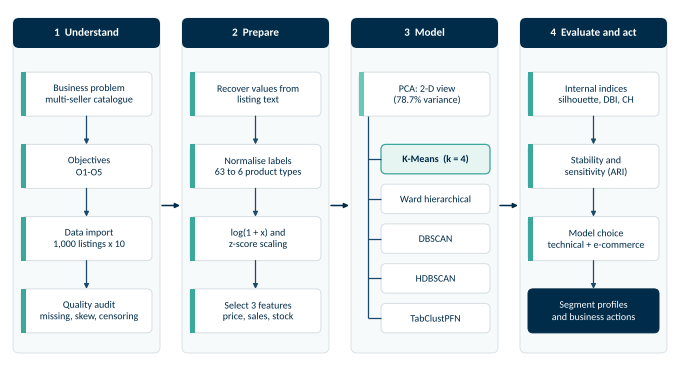

In [54]:
# Figure 15: the workflow, as four phase columns on one grid with the five models as parallel branches
models_in_workflow = [("K-Means  (k = 4)", True), ("Ward hierarchical", False), ("DBSCAN", False), ("HDBSCAN", False),
                      ("TabClustPFN", False)]
H = 3.55
fig, ax = diagram_canvas(H)
gap, x0 = 0.22, 0.03
cw = (TEXT_WIDTH - 2 * x0 - 3 * gap) / 4
xs = [x0 + i * (cw + gap) for i in range(4)]
top, head_h = H - 0.08, 0.30
body_top, body_bot = top - head_h - 0.10, 0.12
for x, title in zip(xs, ["1  Understand", "2  Prepare", "3  Model", "4  Evaluate and act"]):
    ax.add_patch(FancyBboxPatch((x, body_bot), cw, top - body_bot, boxstyle="round,pad=0,rounding_size=0.06",
                                fc=PAPER, ec=GRID, lw=0.6))
    ax.add_patch(FancyBboxPatch((x, top - head_h), cw, head_h, boxstyle="round,pad=0,rounding_size=0.06",
                                fc=MIDNIGHT, ec="none"))
    ax.text(x + cw / 2, top - head_h / 2, title, ha="center", va="center", color="white", fontsize=8, fontweight="bold")
stacks = {
    0: ["Business problem\nmulti-seller catalogue", "Objectives\nO1-O5", "Data import\n1,000 listings x 10",
        "Quality audit\nmissing, skew, censoring"],
    1: ["Recover values from\nlisting text", "Normalise labels\n63 to 6 product types", "log(1 + x) and\nz-score scaling",
        "Select 3 features\nprice, sales, stock"],
    3: ["Internal indices\nsilhouette, DBI, CH", "Stability and\nsensitivity (ARI)", "Model choice\ntechnical + e-commerce",
        "Segment profiles\nand business actions"],
}
bw, bh = cw - 0.16, 0.44
span = body_top - body_bot - 0.06
grid = [body_top - (span / 4) * (i + 0.5) - bh / 2 for i in range(4)]     # one row grid shared by columns 1, 2 and 4
for col, items in stacks.items():
    for i, (text, y) in enumerate(zip(items, grid)):
        last = col == 3 and i == 3
        diagram_box(ax, xs[col] + 0.08, y, bw, bh, text, fc=MIDNIGHT if last else "white", ec=MIDNIGHT if last else GRID,
                    tc="white" if last else MIDNIGHT, size=7.2, accent=None if last else TIFFANY_DEEP)
        if i:
            diagram_arrow(ax, xs[col] + cw / 2, grid[i - 1], xs[col] + cw / 2, y + bh)
diagram_box(ax, xs[2] + 0.08, grid[0], bw, bh, "PCA: 2-D view\n(78.7% variance)", size=7.2, accent=TIFFANY)
n_models = len(models_in_workflow)
top_m, bot_m = grid[1] + bh, grid[3]
mh = min(bh * 0.78, (top_m - bot_m) / (n_models + (n_models - 1) * 0.35))
pitch = (top_m - bot_m - mh) / (n_models - 1)
model_ys = [top_m - mh / 2 - i * pitch for i in range(n_models)]
bus_x = xs[2] + 0.17
diagram_line(ax, [bus_x, bus_x], [grid[0], model_ys[-1]])
for (name, highlighted), yc in zip(models_in_workflow, model_ys):
    diagram_line(ax, [bus_x, xs[2] + 0.30], [yc, yc])
    diagram_box(ax, xs[2] + 0.30, yc - mh / 2, bw - 0.22, mh, name, fc=MIST if highlighted else "white",
                ec=TIFFANY_DEEP if highlighted else GRID, bold=highlighted, size=7.2, lw=0.9 if highlighted else 0.7)
y_mid = (body_top + body_bot) / 2
for i in range(3):
    diagram_arrow(ax, xs[i] + cw + 0.02, y_mid, xs[i + 1] - 0.02, y_mid, color=MIDNIGHT, lw=1.1)
save_figure(fig, "fig15_workflow.png")
plt.show()

Saved: output/figures/fig16_data_prep_flow.png


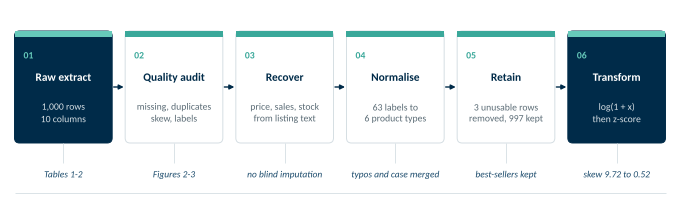

In [55]:
# Figure 16: data-preparation flow, six equal steps with one evidence note under each
steps = [("Raw extract", "1,000 rows\n10 columns"), ("Quality audit", "missing, duplicates\nskew, labels"),
         ("Recover", "price, sales, stock\nfrom listing text"), ("Normalise", "63 labels to\n6 product types"),
         ("Retain", "3 unusable rows\nremoved, 997 kept"), ("Transform", "log(1 + x)\nthen z-score")]
notes = ["Tables 1-2", "Figures 2-3", "no blind imputation", "typos and case merged", "best-sellers kept", "skew 9.72 to 0.52"]
fig, ax = diagram_canvas(1.95)
n_steps, step_gap = len(steps), 0.13
w = (TEXT_WIDTH - 0.09 - step_gap * (n_steps - 1)) / n_steps
y, h = 0.62, 1.12
for i, ((title, sub), note) in enumerate(zip(steps, notes)):
    x = 0.045 + i * (w + step_gap)
    dark = i in (0, n_steps - 1)
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0,rounding_size=0.05",
                                fc=MIDNIGHT if dark else "white", ec=MIDNIGHT if dark else GRID, lw=0.7))
    ax.add_patch(FancyBboxPatch((x, y + h - 0.06), w, 0.06, boxstyle="square,pad=0",
                                fc=TIFFANY if dark else TIFFANY_DEEP, ec="none"))
    ax.text(x + 0.09, y + h - 0.25, format(i + 1, "02d"), color=TIFFANY if dark else TIFFANY_DEEP, fontsize=7,
            fontweight="bold", va="center")
    ax.text(x + w / 2, y + h - 0.47, title, ha="center", va="center", fontsize=8.2, fontweight="bold",
            color="white" if dark else MIDNIGHT)
    ax.text(x + w / 2, y + 0.30, sub, ha="center", va="center", fontsize=7, linespacing=1.2,
            color="#D5DEE3" if dark else MUTE)
    ax.text(x + w / 2, 0.30, note, ha="center", va="center", fontsize=6.8, color=MIDNIGHT_SOFT, style="italic")
    diagram_line(ax, [x + w / 2, x + w / 2], [0.42, y], color=GRID, lw=0.6)
    if i:
        diagram_arrow(ax, x - step_gap + 0.015, y + h / 2, x - 0.015, y + h / 2, color=MIDNIGHT, lw=1.0)
diagram_line(ax, [0.045, TEXT_WIDTH - 0.045], [0.12, 0.12], color=GRID, lw=0.6)
save_figure(fig, "fig16_data_prep_flow.png")
plt.show()

Saved: output/figures/fig17_segment_actions.png


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:158: UserWarning: There are no gridspecs with layoutgrids. Possibly did not call parent GridSpec with the "figure" keyword
  fig.canvas.print_figure(bytes_io, **kw)


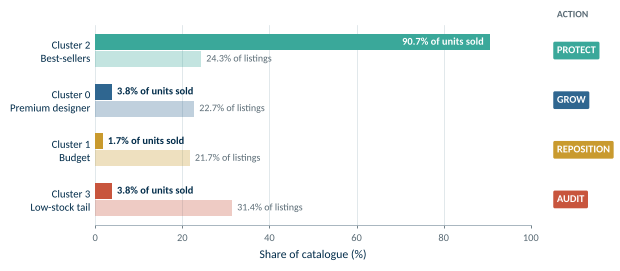

In [56]:
# Figure 17: share of listings vs share of units sold per segment, with the recommended action
action_order = [(2, "Best-sellers", "PROTECT"), (0, "Premium designer", "GROW"), (1, "Budget", "REPOSITION"),
                (3, "Low-stock tail", "AUDIT")]
fig = plt.figure(figsize=(TEXT_WIDTH, 2.7), layout="none")
ax = fig.add_axes([0.17, 0.16, 0.66, 0.74])
for i, (c, name, act) in enumerate(action_order):
    listings_pct = profile.loc[c, "share_of_listings_pct"]
    units_pct = profile.loc[c, "share_of_units_sold_pct"]
    colour = CLUSTER_COLOURS[c]
    ax.barh(i - 0.17, units_pct, height=0.32, color=colour)
    ax.barh(i + 0.17, listings_pct, height=0.32, color=colour, alpha=0.3)
    if units_pct > 60:       # a long bar carries its label inside, so it never meets the action tag
        ax.text(units_pct - 1.5, i - 0.17, format(units_pct, ".1f") + "% of units sold", va="center", ha="right",
                fontsize=7.5, color="white", fontweight="bold")
    else:
        ax.text(units_pct + 1.2, i - 0.17, format(units_pct, ".1f") + "% of units sold", va="center", fontsize=7.5,
                color=MIDNIGHT, fontweight="bold")
    ax.text(listings_pct + 1.2, i + 0.17, format(listings_pct, ".1f") + "% of listings", va="center", fontsize=7.2,
            color=MUTE)
    ax.text(106, i, act, va="center", ha="left", fontsize=7.5, fontweight="bold", color="white", clip_on=False,
            bbox=dict(boxstyle="round,pad=0.35,rounding_size=0.15", fc=colour, ec="none"))
ax.set_yticks(range(len(action_order)))
ax.set_yticklabels(["Cluster " + str(c) + "\n" + n for c, n, _ in action_order], fontsize=7.8, color=MIDNIGHT)
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("Share of catalogue (%)")
ax.tick_params(axis="y", length=0)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
for side in ("left",):
    ax.spines[side].set_visible(False)
ax.text(106, -0.72, "ACTION", fontsize=7, color=MUTE, fontweight="bold", va="center", clip_on=False)
save_figure(fig, "fig17_segment_actions.png")
plt.show()

In [57]:
# Save the frozen results ledger: cluster labels for every listing plus the headline numbers
df[["Item_Name", "details", "product_type", "price", "sold", "stock_level", "stock_imputed",
    "country", "kmeans", "ward", "dbscan", "hdbscan", "tabclustpfn", "tabclustpfn_k4"]].to_csv(OUTPUT_DIR / "cluster_assignments.csv", index=False)

ledger = {
    "rows_raw": int(len(raw)),
    "rows_clean": int(len(df)),
    "features": FEATURES,
    "k_final": K_FINAL,
    "dbscan_eps": EPS_FINAL,
    "dbscan_min_samples": MIN_SAMPLES,
    "hdbscan_min_cluster_size": MIN_CLUSTER_SIZE,
    "hdbscan_min_samples": MIN_SAMPLES,
    "tabclustpfn_checks": tcp_checks,
    "pca_explained_pc1_pc2": [round(float(v), 3) for v in explained[:2]],
    "comparison": comparison.reset_index().to_dict(orient="records"),
    "sensitivity": sensitivity.reset_index().to_dict(orient="records"),
    "kmeans_ward_ari": round(adjusted_rand_score(df["kmeans"], df["ward"]), 3),
    "profiles": profile.reset_index().to_dict(orient="records"),
}
with open(OUTPUT_DIR / "results_ledger.json", "w") as f:
    json.dump(ledger, f, indent=2, default=str)
print("Results ledger saved to", OUTPUT_DIR / "results_ledger.json")

Results ledger saved to output/results_ledger.json
